# Hierarquia e "freguesia" no CS:GO profissional: uma análise em grafos

**Disciplina:** Algoritmos e Estruturas de Dados II · Unidade 01
**Autor:** Ankier José
**Vídeo de apresentação:** link no `README.md`

Este notebook é o roteiro completo do projeto: **dados → tratamento → modelagem → perguntas → conclusões**.
Em cada seção, o texto diz *qual conceito do curso* está sendo usado (com a **semana** em que apareceu) e
*o que a medida significa no problema*. Os blocos de código vêm logo em seguida.

| Seção | Conteúdo | Semanas |
|---|---|---|
| 1 | Problema e perguntas | - |
| 2 | Dados e tratamento (resolução de identidade, filtros) | 6 |
| 3 | Modelagem: grafo de confrontos | 2 |
| 4 | Estrutura global: componentes, caminhos, mundo pequeno | 3, 4 |
| 5 | **Q1** Hierarquia: centralidades vs. ranking HLTV | 2, 4 |
| 6 | **Q1b** Núcleo da elite: k-core / k-shell | 5 |
| 7 | **Q2** Freguesia e intransitividade | 2, 4 |
| 8 | **Q2b** Quão provável é A vencer B? (validação temporal) | 2, 4 |
| 9 | **Q3** Vetos de mapa: bipartido, projeção, Jaccard, camadas | 2, 6 |
| 10 | **Q4** Saltos de vitória até um time-alvo (BFS) | 3 |
| 11 | **Q5** Resiliência: remoção de hubs | 4 |
| 12 | Subredes por ano e comparação com o CS2 (bônus) | 2, 5 |
| 13 | Conclusões, limitações e próximos passos | - |

## 1. Problema e perguntas

**Problema.** O cenário profissional de Counter-Strike é decidido por uma hierarquia simples
("quem tem o melhor ranking ganha") ou existem estruturas que o ranking não captura: times que *sempre*
perdem para um rival específico, ciclos de vitórias, preferências de mapa? Analistas, comissões técnicas,
jogadores e fãs se beneficiam da resposta: preparar vetos, entender confrontos incômodos, antecipar resultados.

**Pergunta central.** *A posição estrutural de um time na rede de confrontos explica seu desempenho
além do ranking HLTV?* A pergunta só faz sentido em rede porque o resultado de um jogo é uma **relação**
entre dois times, não um atributo de um time isolado.

| # | Pergunta | Ferramentas do curso |
|---|---|---|
| Q1 | Quem são os times centrais da rede? Isso coincide com o ranking HLTV? | grau/força, eigenvector, closeness, betweenness (S2, S4) |
| Q1b | Quem forma o núcleo da elite? | k-core, k-shell, core number, onion layers (S5) |
| Q2 | Quem é "freguês" de quem, além do que o ranking explicaria? Há ciclos de intransitividade? | ego network (S2); SCC, triângulos (S4) |
| Q2b | Quão provável é o time A vencer o B? | centralidades calculadas *só com o passado* + baseline de ranking (S2, S4) |
| Q3 | Que mapa cada time tende a banir? Os times banem os mapas em que são mais fracos? | bipartido, projeção $C=B^TB$, Jaccard, multicamadas (S2, S6) |
| Q4 | Quantas "vitórias em cadeia" separam qualquer time de um time-alvo? | BFS, mundo pequeno (S3) |
| Q5 | O que acontece com a rede se removermos os maiores hubs? | componentes, caminho médio (S4) |

## 2. Dados e tratamento

### 2.1 Fonte
- **Dataset:** *CS:GO Professional Matches* (Mateus Dauernheimer Machado, Kaggle):
  `https://www.kaggle.com/datasets/mateusdmachado/csgo-professional-matches`
- **Origem dos dados:** partidas profissionais raspadas do HLTV.org. Período: 11/2015 a 03/2020.
- **Tabelas usadas:** `results.csv` (uma linha por **mapa jogado**, com placar, time vencedor do mapa e ranking
  HLTV dos dois times) e `picks.csv` (uma linha por **partida**, com a sequência de bans/picks do veto).
- **Tabelas não usadas:** `economy.csv` (round a round) e `players.csv` (desempenho individual), pois a
  pergunta é sobre relações entre times. Ficam como extensão futura (rede jogador–time).
- **Obtenção:** `python scripts/baixar_dados.py` (ou download manual dos CSVs para a pasta `data/`).

### 2.2 O que o tratamento precisa resolver
1. **Granularidade:** `results` é por mapa; a rede de confrontos é por **partida** (agrupar por `match_id`).
2. **Identidade (Semana 6):** o mesmo time pode aparecer com grafias diferentes. Isso precisa ser resolvido
   **antes** de montar o grafo; se for feito depois, arestas são duplicadas e as contagens ficam erradas.
3. **Esparsidade:** times com poucas partidas geram ruído. Será usado um filtro de volume mínimo, e o seu
   efeito será mostrado.
4. **Datas de início diferentes por tabela:** os vetos (`picks`) só existem a partir de 2016; as análises de
   veto usam apenas esse recorte.

In [1]:
# --- Importações e parâmetros ------------------------------------------------------------------------
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats, optimize

try:
    import seaborn as sns
except ImportError:          # seaborn é opcional; só melhora alguns gráficos
    sns = None

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ======================= PARÂMETROS (altere aqui) =======================
DATA_DIR = Path("data")          # onde estão results.csv e picks.csv
FIG_DIR = Path("figuras")        # figuras geradas pelo código
OUT_DIR = Path("resultados")     # tabelas e resumo gerados pelo código
SEED = 42

MIN_MATCHES = 15      # nº mínimo de partidas para um time entrar na rede filtrada
MIN_H2H = 4           # nº mínimo de confrontos diretos para falar em "freguesia"
MIN_VETO = 20         # nº mínimo de partidas com veto registrado para analisar os vetos de um time
MIN_MAP_GAMES = 8     # nº mínimo de jogos de um time em um mapa para estimar seu aproveitamento
TEST_FRAC = 0.30      # fração final (cronológica) usada como teste na previsão
TEAM_FOCO = "FURIA"           # time "protagonista" das tabelas (se não existir, usa o mais ativo)
TEAM_ALVO = "Natus Vincere"   # alvo da busca em largura (Q4)
RUN_RESILIENCE = True         # a seção Q5 é a mais lenta; desligue se precisar
CS2_FILE = DATA_DIR / "cs2_results.csv"   # opcional (dataset ilyazored/hltv-match-resultscs2)

# Se, ao rodar o bloco de identidade, você notar apelidos que a normalização automática não une
# (ex.: "NaVi" e "Natus Vincere"), registre aqui: {grafia_encontrada: nome_canônico}
ALIASES = {}
# ========================================================================

FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
RESULTS = {}   # acumula os números que alimentam o resumo final (seção 13)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})


# --- Funções utilitárias reutilizadas ao longo do notebook -------------------------------------------
def savefig(name):
    """Salva a figura corrente em figuras/<name>.png (as figuras do README vêm do código)."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def norm_key(s):
    """Chave de normalização de nomes: minúsculas e só letras/números."""
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def norm_map(x):
    """Padroniza nomes de mapa: 'de_dust2', 'Dust2 ' -> 'Dust2'."""
    return re.sub(r"^de_", "", str(x).strip().lower()).title()


def build_win_graph(m, win="winner", lose="loser"):
    """DiGraph PERDEDOR -> VENCEDOR; weight = nº de partidas que o destino venceu contra a origem."""
    agg = m.groupby([lose, win]).size().rename("weight").reset_index()
    g = nx.DiGraph()
    g.add_weighted_edges_from(agg[[lose, win, "weight"]].itertuples(index=False, name=None))
    return g


def to_undirected_weighted(g):
    """Versão não dirigida (soma os pesos das duas direções)."""
    u = nx.Graph()
    for a, b, d in g.edges(data=True):
        if u.has_edge(a, b):
            u[a][b]["weight"] += d["weight"]
        else:
            u.add_edge(a, b, weight=d["weight"])
    return u


def largest_cc(u):
    return u.subgraph(max(nx.connected_components(u), key=len)).copy()


def path_stats(ug, max_exact=1500, n_src=300):
    """Caminho médio e diâmetro (BFS). Se o grafo for grande, amostra origens (diâmetro vira limite inferior)."""
    nodes = list(ug.nodes)
    exact = len(nodes) <= max_exact
    idx = range(len(nodes)) if exact else rng.choice(len(nodes), n_src, replace=False)
    tot = cnt = ecc = 0
    for i in idx:
        d = nx.single_source_shortest_path_length(ug, nodes[i])
        tot += sum(d.values()); cnt += len(d) - 1; ecc = max(ecc, max(d.values()))
    return {"avg": tot / cnt if cnt else np.nan, "diameter": ecc, "exact": exact}


def fit_logit(X, y, l2=1e-3):
    """Regressão logística (com intercepto) por L-BFGS. X: (n×k)."""
    X = np.column_stack([np.ones(len(X)), np.asarray(X, float)]); y = np.asarray(y, float)

    def nll(w):
        z = X @ w
        return np.sum(np.logaddexp(0, z) - y * z) + 0.5 * l2 * np.sum(w[1:] ** 2)

    def grad(w):
        p = 1 / (1 + np.exp(-(X @ w)))
        g = X.T @ (p - y); g[1:] += l2 * w[1:]
        return g

    return optimize.minimize(nll, np.zeros(X.shape[1]), jac=grad, method="L-BFGS-B").x


def predict_logit(w, X):
    X = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
    return 1 / (1 + np.exp(-(X @ w)))


def clf_metrics(y, p):
    y = np.asarray(y, float); p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return {"acc": float(np.mean((p > 0.5) == (y == 1))),
            "logloss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))),
            "brier": float(np.mean((p - y) ** 2))}


def bh_fdr(p):
    """Correção de Benjamini-Hochberg (q-values) para testes múltiplos."""
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    q = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1)
    return out


def weighted_jaccard(P):
    """Jaccard ponderado entre as linhas de P (n×m): Σ min / Σ max."""
    mins = np.minimum(P[:, None, :], P[None, :, :]).sum(-1)
    maxs = np.maximum(P[:, None, :], P[None, :, :]).sum(-1)
    return np.divide(mins, maxs, out=np.zeros_like(mins), where=maxs > 0)


def resolve_team(name, valid, fallback, label):
    """Acha `name` entre os nós; se não existir, usa `fallback` e avisa."""
    if name in valid:
        return name
    k = norm_key(name)
    for t in valid:
        if norm_key(t) == k:
            return t
    print(f"⚠️ {label}: '{name}' não encontrado; usando '{fallback}'.")
    return fallback

### 2.3 Carregamento
Os arquivos são localizados sem diferenciar maiúsculas/minúsculas, e as colunas indispensáveis são
conferidas logo no início: se algo estiver diferente do esperado, o erro aparece aqui, não no meio da análise.

In [2]:
def find_csv(stem):
    hits = [p for p in DATA_DIR.glob("*.csv") if p.stem.lower() == stem]
    if not hits:
        raise FileNotFoundError(f"'{stem}.csv' não encontrado em {DATA_DIR.resolve()}. "
                                f"Rode `python scripts/baixar_dados.py` ou copie os CSVs para a pasta.")
    return hits[0]


results_raw = pd.read_csv(find_csv("results"))
picks_raw = pd.read_csv(find_csv("picks"))

NEEDED = {"date", "team_1", "team_2", "_map", "result_1", "result_2", "map_winner", "match_id", "rank_1", "rank_2"}
missing = NEEDED - set(results_raw.columns)
assert not missing, f"results.csv sem as colunas {missing}; colunas encontradas: {list(results_raw.columns)}"

print(f"results.csv: {results_raw.shape[0]:,} linhas (mapas) × {results_raw.shape[1]} colunas")
print(f"picks.csv:   {picks_raw.shape[0]:,} linhas (partidas) × {picks_raw.shape[1]} colunas")
print("\nColunas de picks:", list(picks_raw.columns))
results_raw.head(3)

results.csv: 45,773 linhas (mapas) × 19 colunas
picks.csv:   16,035 linhas (partidas) × 17 colunas

Colunas de picks: ['date', 'team_1', 'team_2', 'inverted_teams', 'match_id', 'event_id', 'best_of', 'system', 't1_removed_1', 't1_removed_2', 't1_removed_3', 't2_removed_1', 't2_removed_2', 't2_removed_3', 't1_picked_1', 't2_picked_1', 'left_over']


,date,team_1,team_2,_map,result_1,result_2,map_winner,starting_ct,ct_1,t_2,t_1,ct_2,event_id,match_id,rank_1,rank_2,map_wins_1,map_wins_2,match_winner
0,2020-03-18,Recon 5,TeamOne,Dust2,0,16,2,2,0,1,0,15,5151,2340454,62,63,0,2,2
1,2020-03-18,Recon 5,TeamOne,Inferno,13,16,2,2,8,6,5,10,5151,2340454,62,63,0,2,2
2,2020-03-18,New England Whalers,Station7,Inferno,12,16,2,1,9,6,3,10,5243,2340461,140,118,12,16,2


### 2.4 Limpeza de tipos e datas
Descartamos linhas sem data, times ou vencedor do mapa, e mantemos apenas `map_winner ∈ {1, 2}`
(1 = `team_1` venceu o mapa; 2 = `team_2`).

In [3]:
res = results_raw.copy()
res["date"] = pd.to_datetime(res["date"], errors="coerce")
for c in ["rank_1", "rank_2", "map_winner"]:
    res[c] = pd.to_numeric(res[c], errors="coerce")
n0 = len(res)
res = res.dropna(subset=["date", "team_1", "team_2", "match_id", "map_winner"])
res = res[res["map_winner"].isin([1, 2])].copy()
res["map_winner"] = res["map_winner"].astype(int)
res["map"] = res["_map"].map(norm_map)
print(f"Linhas removidas na limpeza: {n0 - len(res):,} de {n0:,}")
print(f"Período em results: {res.date.min().date()} → {res.date.max().date()}")
print("Mapas encontrados:", res["map"].value_counts().to_dict())

Linhas removidas na limpeza: 0 de 45,773
Período em results: 2015-11-03 → 2020-03-18
Mapas encontrados: {'Mirage': 9021, 'Inferno': 7485, 'Train': 6566, 'Overpass': 5625, 'Cache': 4613, 'Nuke': 4206, 'Dust2': 4114, 'Cobblestone': 3513, 'Vertigo': 609, 'Default': 21}


### 2.5 Resolução de identidade (Semana 6)
**Contrato:** cada time deve ter exatamente um nome. A normalização automática une grafias que só diferem por
maiúsculas, espaços e pontuação (ex.: `"G2 "` e `"g2"`), escolhendo como canônico o nome mais frequente.
O que a regra não une (ex.: `"NaVi"` × `"Natus Vincere"`) pode ser corrigido manualmente em `ALIASES`
(parâmetros, no início). **Esta etapa vem antes de qualquer grafo.**

In [4]:
def build_canon(*series):
    """Mapa chave-normalizada -> nome canônico (grafia mais frequente)."""
    s = pd.concat([x.astype(str).str.strip() for x in series])
    freq = s.value_counts()
    canon = {}
    for name in freq.index:                      # freq está em ordem decrescente
        canon.setdefault(norm_key(name), name)
    return canon, freq


CANON, name_freq = build_canon(res.team_1, res.team_2, picks_raw["team_1"], picks_raw["team_2"])


def canon_name(x, canon=None):
    s = str(x).strip()
    s = ALIASES.get(s, s)
    return (canon or CANON).get(norm_key(s), s)


# Relatório: grafias distintas que a normalização uniu
groups = {}
for name in name_freq.index:
    groups.setdefault(norm_key(name), []).append(name)
merged = {CANON[k]: v for k, v in groups.items() if len(v) > 1}
print(f"Nomes brutos distintos: {len(name_freq):,} → times canônicos: {len(CANON):,}")
print(f"Grupos unidos automaticamente: {len(merged)}")
for k, v in list(merged.items())[:10]:
    print(f"  {k!r} ← {v}")

res["team_1"] = res["team_1"].map(canon_name)
res["team_2"] = res["team_2"].map(canon_name)

Nomes brutos distintos: 1,553 → times canônicos: 1,542
Grupos unidos automaticamente: 11
  'Imperial' ← ['Imperial', 'imperial']
  'Chaos' ← ['Chaos', 'CHAOS']
  'FIVE' ← ['FIVE', 'FiVe']
  'Infamous' ← ['Infamous', 'InFamous']
  'ROAR' ← ['ROAR', 'Roar']
  'Demise' ← ['Demise', 'demise']
  'NOVA' ← ['NOVA', 'Nova']
  'Sinners' ← ['Sinners', 'SinnerS']
  'Good Fellas' ← ['Good Fellas', 'Goodfellas']
  'WE GOT GAME' ← ['WE GOT GAME', 'WeGotGame']


### 2.6 De mapas para partidas
A unidade da rede de confrontos é a **partida**. Para cada `match_id` contamos quantos mapas cada lado
venceu; vence a partida quem venceu mais mapas. Partidas empatadas ou com times trocados de lugar entre os
mapas são descartadas (e contadas, para transparência). O ranking da partida é a mediana de `rank_1`/`rank_2`
entre os seus mapas.

In [5]:
chk = res.groupby("match_id").agg(n1=("team_1", "nunique"), n2=("team_2", "nunique"))
bad_ids = chk[(chk.n1 > 1) | (chk.n2 > 1)].index
res_ok = res[~res.match_id.isin(bad_ids)].copy()
res_ok["w1"] = (res_ok.map_winner == 1).astype(int)
res_ok["w2"] = (res_ok.map_winner == 2).astype(int)

agg = dict(date=("date", "min"), team_1=("team_1", "first"), team_2=("team_2", "first"),
           maps1=("w1", "sum"), maps2=("w2", "sum"), n_maps=("w1", "size"),
           rank_1=("rank_1", "median"), rank_2=("rank_2", "median"))
if "event_id" in res_ok.columns:
    agg["event_id"] = ("event_id", "first")
matches = res_ok.groupby("match_id").agg(**agg).reset_index()

n_all = len(matches)
matches = matches[(matches.maps1 != matches.maps2) & (matches.team_1 != matches.team_2)].copy()
matches["y"] = (matches.maps1 > matches.maps2).astype(int)         # 1 = team_1 venceu
matches["winner"] = np.where(matches.y == 1, matches.team_1, matches.team_2)
matches["loser"] = np.where(matches.y == 1, matches.team_2, matches.team_1)
matches = matches.sort_values("date").reset_index(drop=True)

print(f"Partidas (match_id) distintas: {n_all:,}")
print(f"  descartadas por times inconsistentes entre mapas: {len(bad_ids):,}")
print(f"  descartadas por empate/auto-confronto: {n_all - len(matches):,}")
print(f"Partidas válidas: {len(matches):,} · times distintos: {pd.concat([matches.team_1, matches.team_2]).nunique():,}")
RESULTS.update(n_matches_valid=len(matches), n_teams_all=int(pd.concat([matches.team_1, matches.team_2]).nunique()))

Partidas (match_id) distintas: 27,245
  descartadas por times inconsistentes entre mapas: 0
  descartadas por empate/auto-confronto: 464
Partidas válidas: 26,781 · times distintos: 1,539


### 2.7 Filtro de volume mínimo (e o seu efeito)
Times com pouquíssimas partidas têm graus mínimos e poucas informações, e distorcem centralidade e k-core.
O filtro mantém só partidas em que **ambos** os times têm ao menos `MIN_MATCHES` partidas. A tabela mostra
como a escolha do limiar muda o tamanho da rede (a escolha não é neutra e fica documentada).

In [6]:
games = pd.concat([matches.team_1, matches.team_2]).value_counts()
rows = []
for thr in [1, 5, 10, 15, 25, 50, 100]:
    keep = set(games[games >= thr].index)
    mk = matches[matches.team_1.isin(keep) & matches.team_2.isin(keep)]
    rows.append({"limiar": thr, "times": len(keep), "partidas": len(mk), "% partidas mantidas": round(100 * len(mk) / len(matches), 1)})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))

keep = set(games[games >= MIN_MATCHES].index)
matches_f = matches[matches.team_1.isin(keep) & matches.team_2.isin(keep)].reset_index(drop=True)
print(f"\nLimiar adotado: {MIN_MATCHES} → {len(keep):,} times · {len(matches_f):,} partidas")
sens.to_csv(OUT_DIR / "sensibilidade_filtro.csv", index=False)

 limiar  times  partidas  % partidas mantidas
      1   1539     26781                100.0
      5    894     25610                 95.6
     10    654     24179                 90.3
     15    531     22973                 85.8
     25    393     20955                 78.2
     50    212     16650                 62.2
    100    129     13305                 49.7

Limiar adotado: 15 → 531 times · 22,973 partidas


## 3. Modelagem: o grafo de confrontos (Semana 2)

| Elemento | Definição |
|---|---|
| **Nó** | time (nome canônico) |
| **Aresta** | existe se os dois times se enfrentaram ao menos uma vez |
| **Direção** | **perdedor → vencedor** (grafo dirigido, `DiGraph`) |
| **Peso** | nº de partidas que o vencedor ganhou do perdedor |
| **Fica de fora** | trocas de elenco (um nó é um *rótulo*), LAN vs online, nível do torneio, rounds, mapa |

**Por que perdedor → vencedor?** Assim o **grau de entrada ponderado** de um nó é o seu total de vitórias e o
grau de saída, o de derrotas. Na centralidade de autovetor, a pontuação de um time soma a pontuação dos times
que ele venceu, isto é, "quem vence quem vence muito". A direção leva a informação (A→B ≠ B→A), então
um grafo não dirigido perderia justamente a hierarquia.

**Alternativas consideradas:** (i) multigrafo/multicamada por mapa, usado na seção 9; (ii) grafo temporal por ano,
usado na seção 12; (iii) grafo bipartido time×mapa para os vetos, usado na seção 9.

In [7]:
G_all = build_win_graph(matches)        # sem filtro
G = build_win_graph(matches_f)          # rede de trabalho
U = to_undirected_weighted(G)           # versão não dirigida (para caminhos, closeness, k-core...)

N, L = G.number_of_nodes(), G.number_of_edges()
dens = nx.density(G)                    # L / [N(N-1)]  (direcionado simples)
print(f"Rede de trabalho: N = {N:,} nós · L = {L:,} arestas dirigidas · densidade d = {dens:.4f}")
print(f"Grau médio de entrada (= saída) ⟨k_in⟩ = L/N = {L / N:.2f}")
print(f"Rede sem filtro:  N = {G_all.number_of_nodes():,} · L = {G_all.number_of_edges():,} · d = {nx.density(G_all):.5f}")
RESULTS.update(N=N, L=L, density=dens)

# Matriz de adjacência (esparsa) — mostra que a rede é esparsa e assimétrica
A = nx.to_scipy_sparse_array(G, weight="weight", format="csr")
print(f"Matriz de adjacência {A.shape[0]}×{A.shape[1]} com {A.nnz:,} entradas não nulas "
      f"({100 * A.nnz / (A.shape[0] ** 2):.2f}% preenchida)")

Rede de trabalho: N = 531 nós · L = 11,314 arestas dirigidas · densidade d = 0.0402
Grau médio de entrada (= saída) ⟨k_in⟩ = L/N = 21.31
Rede sem filtro:  N = 1,539 · L = 14,799 · d = 0.00625
Matriz de adjacência 531×531 com 11,314 entradas não nulas (4.01% preenchida)


**Distribuição de graus (Semana 2).** Em redes reais, poucos nós concentram muitas conexões (*hubs*).
Abaixo, a distribuição do número de adversários distintos e da força de vitórias; escala log-log.
Se a cauda é longa, a média ⟨k⟩ descreve mal a rede.

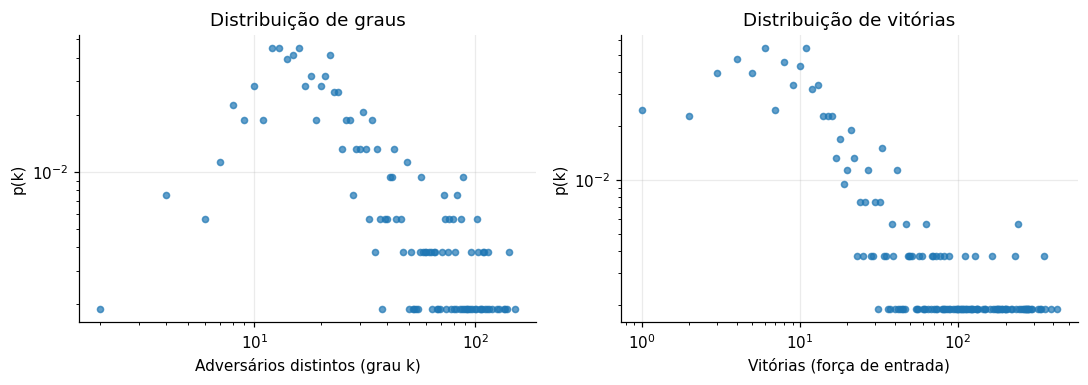

Grau: média 33.6 · mediana 22 · máx 152 → razão máx/mediana = 6.9


In [8]:
deg = pd.Series(dict(U.degree()))                               # adversários distintos
win_strength = pd.Series(dict(G.in_degree(weight="weight")))    # vitórias
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, s, t in zip(ax, [deg, win_strength], ["Adversários distintos (grau k)", "Vitórias (força de entrada)"]):
    vc = s.value_counts().sort_index()
    a.loglog(vc.index, vc.values / vc.sum(), "o", ms=4, alpha=.7)
    a.set_xlabel(t); a.set_ylabel("p(k)")
ax[0].set_title("Distribuição de graus"); ax[1].set_title("Distribuição de vitórias")
savefig("01_distribuicao_graus"); plt.show()
print(f"Grau: média {deg.mean():.1f} · mediana {deg.median():.0f} · máx {deg.max()} → razão máx/mediana = {deg.max() / deg.median():.1f}")
RESULTS.update(deg_mean=float(deg.mean()), deg_median=float(deg.median()), deg_max=int(deg.max()))

## 4. Estrutura global (Semanas 3 e 4)

- **Componentes (S4):** *fracamente conexo* (WCC) ignora a direção; *fortemente conexo* (SCC) exige caminho de
  ida e volta. O maior WCC é o **componente gigante (GCC)**. O maior SCC mostra quantos times estão num "miolo" onde
  todos conseguem alcançar todos por cadeias de vitórias.
- **Caminho médio e diâmetro (S4):** quão longe estão dois times quaisquer. Caminhos curtos com agrupamento
  alto caracterizam **mundo pequeno (S3)**.
- **Clustering (S4):** fração de "adversários dos meus adversários" que também me enfrentaram.
- **Referência:** comparamos com um grafo aleatório $G(n,m)$ com o mesmo número de nós e arestas, e
  calculamos o coeficiente de mundo pequeno σ = (C/C_rand) / (L/L_rand). Valores bem acima de 1 indicam mundo pequeno.

In [9]:
wcc = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
scc = sorted(nx.strongly_connected_components(G), key=len, reverse=True)
U_gcc = U.subgraph(wcc[0]).copy()
print(f"Componentes fracamente conexos: {len(wcc)} · GCC = {len(wcc[0])} nós ({100 * len(wcc[0]) / N:.1f}%)")
print(f"Componentes fortemente conexos: {len(scc)} · maior SCC = {len(scc[0])} nós ({100 * len(scc[0]) / N:.1f}%)")

ps = path_stats(U_gcc)
C = nx.average_clustering(U_gcc)
T = nx.transitivity(U_gcc)

# referência aleatória G(n, m) com o mesmo tamanho do GCC
n_g, m_g = U_gcc.number_of_nodes(), U_gcc.number_of_edges()
R = nx.gnm_random_graph(n_g, m_g, seed=SEED)
R_gcc = largest_cc(R)
ps_r = path_stats(R_gcc)
C_r = nx.average_clustering(R_gcc)
sigma = (C / C_r) / (ps["avg"] / ps_r["avg"])

print(f"\nCaminho médio  L = {ps['avg']:.2f}  (aleatório: {ps_r['avg']:.2f}) · diâmetro = {ps['diameter']}"
      f"{'' if ps['exact'] else ' (limite inferior, amostrado)'}")
print(f"Clustering     C = {C:.3f}  (aleatório: {C_r:.3f}) · transitividade = {T:.3f}")
print(f"Mundo pequeno  σ = {sigma:.1f}")
RESULTS.update(gcc_frac=len(wcc[0]) / N, scc_frac=len(scc[0]) / N, avg_path=ps["avg"], diameter=ps["diameter"],
               avg_path_rand=ps_r["avg"], clustering=C, clustering_rand=C_r, sigma=sigma, n_wcc=len(wcc), n_scc=len(scc))

Componentes fracamente conexos: 1 · GCC = 531 nós (100.0%)
Componentes fortemente conexos: 6 · maior SCC = 526 nós (99.1%)

Caminho médio  L = 2.43  (aleatório: 2.05) · diâmetro = 4
Clustering     C = 0.519  (aleatório: 0.063) · transitividade = 0.381
Mundo pequeno  σ = 6.9


## 5. Q1: Hierarquia: quem é central, e isso coincide com o ranking HLTV? (Semanas 2 e 4)

O que cada medida significa **neste problema**:

| Medida | Semana | Leitura no CS |
|---|---|---|
| Força de entrada (vitórias) / razão de vitórias | 2 | volume bruto de sucesso |
| Nº de adversários (grau) | 2 | diversidade de confrontos (reflete calendário, não só força) |
| Closeness | 4 | quão "perto" o time está de todos os outros: circula por vários cenários |
| Betweenness | 4 | times que são **ponte** entre regiões/grupos |
| **Eigenvector** (rede perdedor→vencedor) | 4 | vencer times que vencem muito; qualidade das vitórias |
| PageRank *(fora do curso, só como checagem)* | - | variante robusta da ideia do autovetor |

O autovetor é calculado no **maior SCC**, onde ele é bem definido; os demais times ficam sem valor (`NaN`).
A validação externa é o **ranking HLTV**: se a estrutura da rede capta a força real, as centralidades devem
se correlacionar com o ranking (correlação de Spearman **negativa**, pois ranking 1 é o melhor).

In [10]:
wins = pd.Series(dict(G.in_degree(weight="weight")))
losses = pd.Series(dict(G.out_degree(weight="weight")))
cent = pd.DataFrame({"wins": wins, "losses": losses})
cent["n_matches"] = cent.wins + cent.losses
cent["win_ratio"] = cent.wins / cent.n_matches
cent["opponents"] = pd.Series(dict(U.degree()))

# autovetor no maior SCC
H = G.subgraph(scc[0]).copy()
try:
    ev = nx.eigenvector_centrality_numpy(H, weight="weight", max_iter=1000)
except Exception as e:
    print("eigenvector_numpy falhou, usando iteração de potência:", e)
    ev = nx.eigenvector_centrality(H, weight="weight", max_iter=5000, tol=1e-8)
cent["eig"] = pd.Series(ev).abs()

# closeness e betweenness no GCC (não dirigido); betweenness amostrada se o grafo for grande
cent["closeness"] = pd.Series(nx.closeness_centrality(U_gcc))
k_b = None if U_gcc.number_of_nodes() <= 800 else 400
cent["betweenness"] = pd.Series(nx.betweenness_centrality(U_gcc, k=k_b, seed=SEED))
cent["pagerank"] = pd.Series(nx.pagerank(G, weight="weight"))

# ranking HLTV: mediana do ranking do time ao longo das partidas
rk = pd.concat([matches_f[["team_1", "rank_1"]].set_axis(["team", "rank"], axis=1),
                matches_f[["team_2", "rank_2"]].set_axis(["team", "rank"], axis=1)])
rk = rk[rk["rank"] > 0]
cent["rank_median"] = rk.groupby("team")["rank"].median()

print(f"Autovetor definido para {cent.eig.notna().sum()} de {len(cent)} times (maior SCC).")
print("Betweenness " + ("exata." if k_b is None else f"aproximada com k={k_b} pivôs (amostragem)."))

Autovetor definido para 526 de 531 times (maior SCC).
Betweenness exata.


In [11]:
measures = ["wins", "win_ratio", "opponents", "eig", "closeness", "betweenness", "pagerank"]
rows = []
for c in measures:
    d = cent[[c, "rank_median"]].dropna()
    rho, p = stats.spearmanr(d[c], d["rank_median"])
    rows.append({"medida": c, "rho_vs_ranking": rho, "p_valor": p, "n_times": len(d)})
corr_rank = pd.DataFrame(rows).sort_values("rho_vs_ranking")
print("Correlação de Spearman entre cada medida e o ranking HLTV (esperado: negativa, pois 1 = melhor):\n")
print(corr_rank.round(3).to_string(index=False))
corr_rank.to_csv(OUT_DIR / "q1_correlacao_ranking.csv", index=False)
RESULTS["corr_rank"] = corr_rank.set_index("medida")["rho_vs_ranking"].to_dict()

top = cent.sort_values("eig", ascending=False).head(15)[["wins", "losses", "win_ratio", "opponents", "eig", "betweenness", "rank_median"]]
print("\nTop 15 por autovetor:")
print(top.round(3).to_string())
top.to_csv(OUT_DIR / "q1_top15_autovetor.csv")

Correlação de Spearman entre cada medida e o ranking HLTV (esperado: negativa, pois 1 = melhor):

     medida  rho_vs_ranking  p_valor  n_times
        eig          -0.816      0.0      526
  closeness          -0.743      0.0      531
   pagerank          -0.682      0.0      531
  win_ratio          -0.658      0.0      531
       wins          -0.640      0.0      531
  opponents          -0.584      0.0      531
betweenness          -0.514      0.0      531

Top 15 por autovetor:
               wins  losses  win_ratio  opponents    eig  betweenness  rank_median
Astralis        423     180      0.701         66  0.391        0.004          2.0
FaZe            350     251      0.582         60  0.308        0.003          5.0
fnatic          331     235      0.585         71  0.288        0.005         10.0
NiP             318     259      0.551         72  0.275        0.005          8.0
mousesports     350     255      0.579         76  0.274        0.004         10.0
G2           

**Centralidades concordam entre si?** (S4: matriz de correlação / PairGrid). Em redes reais, medidas
diferentes capturam coisas diferentes. Baixa concordância é informação, não defeito. Usamos percentis para
comparar escalas distintas.

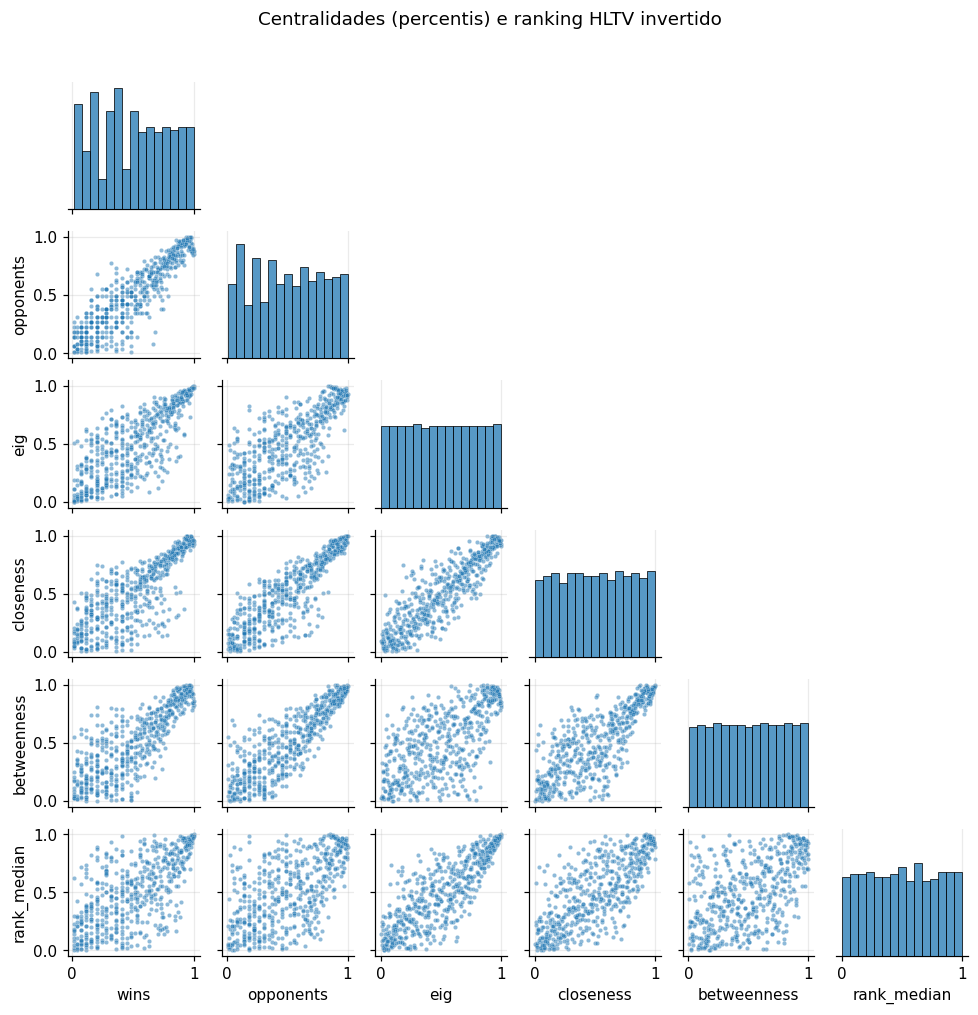

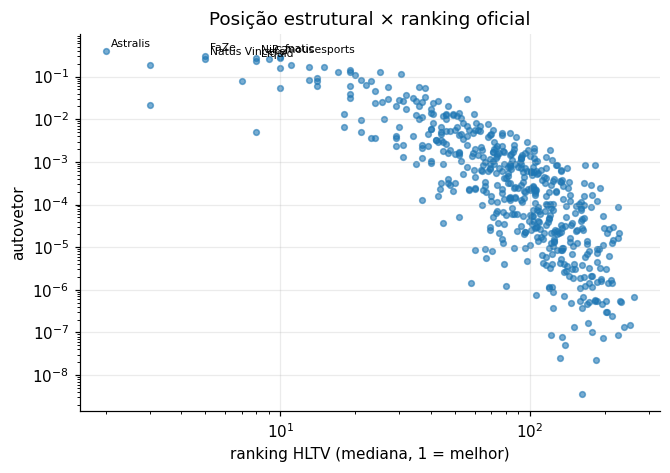

In [12]:
pct = cent[["wins", "opponents", "eig", "closeness", "betweenness", "rank_median"]].rank(pct=True)
pct["rank_median"] = 1 - pct["rank_median"]          # inverte: maior = melhor ranking
if sns is not None:
    g = sns.PairGrid(pct.dropna(), corner=True, height=1.5)
    g.map_lower(sns.scatterplot, s=8, alpha=.5)
    g.map_diag(sns.histplot, bins=15)
    plt.suptitle("Centralidades (percentis) e ranking HLTV invertido", y=1.02)
else:
    pd.plotting.scatter_matrix(pct.dropna(), figsize=(8, 8), s=8)
savefig("02_pairgrid_centralidades"); plt.show()

# Eigenvector vs ranking
d = cent.dropna(subset=["eig", "rank_median"])
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(d.rank_median, d.eig, s=14, alpha=.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ranking HLTV (mediana, 1 = melhor)"); ax.set_ylabel("autovetor")
for t in d.sort_values("eig", ascending=False).head(8).index:
    ax.annotate(t, (d.loc[t, "rank_median"], d.loc[t, "eig"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("Posição estrutural × ranking oficial")
savefig("03_autovetor_vs_ranking"); plt.show()

## 6. Q1b: Núcleo da elite: k-core e k-shell (Semana 5)

O grau só diz **quantos** adversários um time teve; não diz se ele está num grupo coeso. O **k-core** é o maior
subgrafo onde todo nó tem grau ≥ k *dentro* dele; o procedimento remove, iterativamente, os nós de grau < k.
O **core number** (coreness) de um time é o maior k para o qual ele sobrevive. O **k-shell** é a "casca" com
coreness exatamente k, e o maior k define o **núcleo interno** (innermost core). **Onion layers** refina a ordem de
remoção dentro de cada shell.

**Leitura no CS:** o núcleo é o conjunto de times que se enfrentam muito entre si, a "elite" do circuito.
**Cuidado:** k-core usa o *número de adversários distintos*, que depende do calendário (times de torneios
abertos enfrentam mais gente). O resultado é uma estrutura de **encontros**, não necessariamente de **força**;
por isso comparamos com o ranking.

In [13]:
Us = nx.Graph(U)
Us.remove_edges_from(nx.selfloop_edges(Us))
core = nx.core_number(Us)
onion = nx.onion_layers(Us)
cent["core"] = pd.Series(core)
cent["onion"] = pd.Series(onion)
kmax = max(core.values())
innermost = [n for n, c in core.items() if c == kmax]
shell_sizes = pd.Series(core).value_counts().sort_index()

print(f"Degenerescência (k máximo) = {kmax} · núcleo interno com {len(innermost)} times")
print("Times do núcleo interno:", ", ".join(sorted(innermost, key=lambda t: -cent.loc[t, 'wins'])[:25]))

d = cent.dropna(subset=["rank_median"])
rho_core_rank = stats.spearmanr(d["core"], d["rank_median"])[0]
rho_core_deg = stats.spearmanr(cent["core"], cent["opponents"])[0]
print(f"\nSpearman(core, ranking HLTV) = {rho_core_rank:.3f} · Spearman(core, nº de adversários) = {rho_core_deg:.3f}")
by_shell = cent.groupby("core").agg(times=("wins", "size"), rank_mediano=("rank_median", "median"), razao_vitorias=("win_ratio", "mean")).round(3)
print("\nPerfil por k-shell:")
print(by_shell.tail(8).to_string())
by_shell.to_csv(OUT_DIR / "q1b_perfil_kshell.csv")
RESULTS.update(kmax=kmax, n_innermost=len(innermost), rho_core_rank=rho_core_rank, rho_core_deg=rho_core_deg)

Degenerescência (k máximo) = 34 · núcleo interno com 73 times
Times do núcleo interno: Astralis, Liquid, FaZe, mousesports, G2, fnatic, NiP, Natus Vincere, OpTic, NRG, Virtus.pro, Renegades, Spirit, AGO, HellRaisers, Tricked, Heroic, Envy, TYLOO, AVANGAR, North, ALTERNATE aTTaX, Epsilon, Kinguin, HAVU

Spearman(core, ranking HLTV) = -0.660 · Spearman(core, nº de adversários) = 0.918

Perfil por k-shell:
      times  rank_mediano  razao_vitorias
core                                     
27        5         42.00           0.504
28        5         41.00           0.508
29        2         56.50           0.501
30        6         58.50           0.445
31        2         41.25           0.462
32        7         38.00           0.463
33        8         47.50           0.557
34       73         36.00           0.520


In [14]:
%pip install nxviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 9.1 MB/s eta 0:00:00


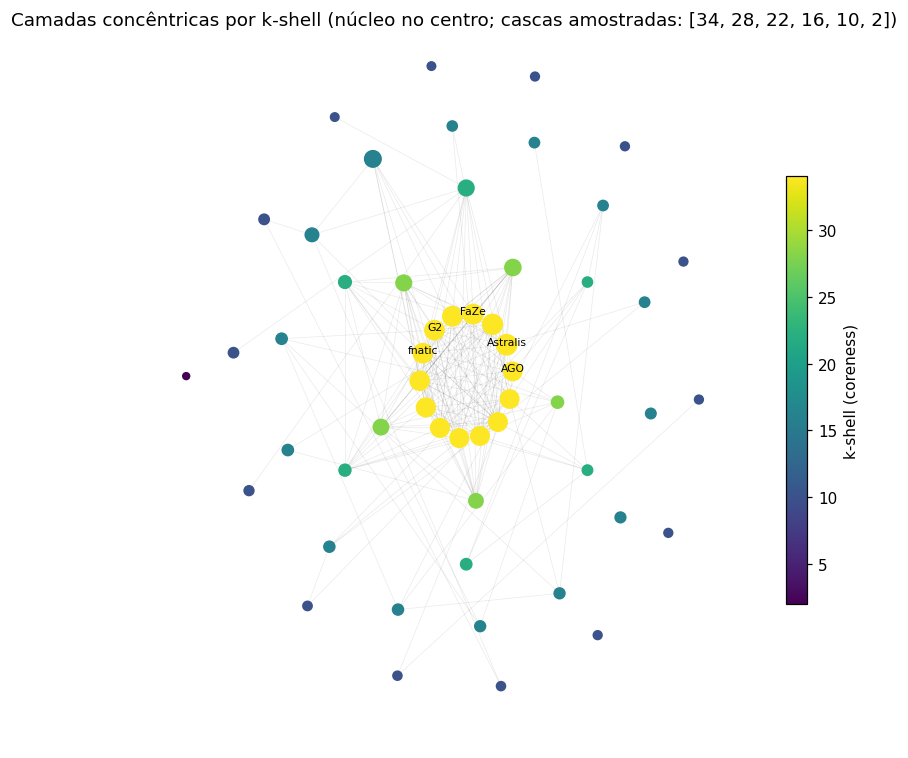

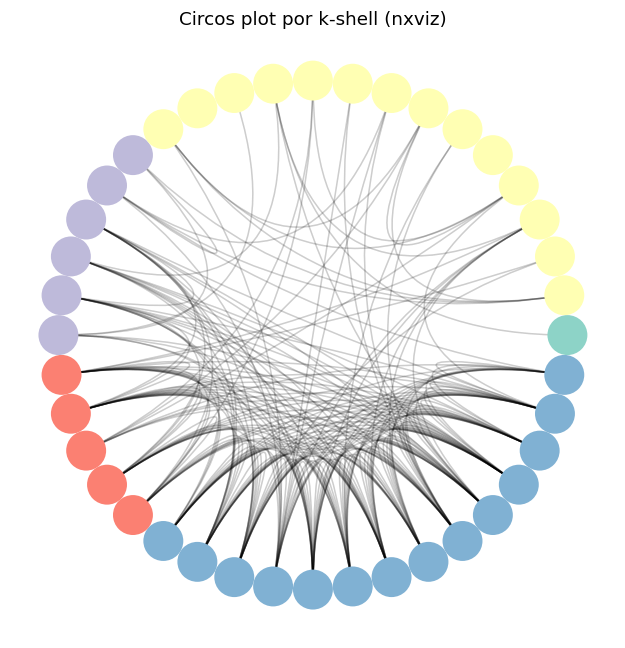

In [15]:
# Visualização hierárquica: camadas concêntricas por k-shell (núcleo no centro).
# Para enxergar os anéis, amostramos até 6 cascas espalhadas de k_max até a periferia, com até 14 times por casca
# (os de mais vitórias). Se houver poucas cascas distintas, todas são usadas.
ks = sorted(set(core.values()), reverse=True)
k_sel = sorted({ks[int(i)] for i in np.linspace(0, len(ks) - 1, min(6, len(ks)))}, reverse=True)
shells = [sorted([n for n in core if core[n] == k], key=lambda t: -cent.loc[t, "wins"])[:14] for k in k_sel]
sel = [n for sh in shells for n in sh]
Hs = Us.subgraph(sel).copy()
pos = nx.shell_layout(Hs, nlist=shells)
fig, ax = plt.subplots(figsize=(7, 7))
nx.draw_networkx_edges(Hs, pos, alpha=.08, width=.5, ax=ax)
nc = [core[n] for n in Hs]
nodes_art = nx.draw_networkx_nodes(Hs, pos, node_color=nc, cmap="viridis", node_size=[20 + 2.5 * np.sqrt(cent.loc[n, "wins"]) * 3 for n in Hs], ax=ax)
for n in innermost[:12]:
    if n in pos:
        ax.annotate(n, pos[n], fontsize=7, ha="center")
plt.colorbar(nodes_art, ax=ax, shrink=.6, label="k-shell (coreness)")
ax.set_title(f"Camadas concêntricas por k-shell (núcleo no centro; cascas amostradas: {k_sel})"); ax.axis("off")
savefig("04_kshell_concentrico"); plt.show()

# Alternativa recomendada pelo curso (Semana 4): nxviz. Se a versão instalada falhar, usamos Matplotlib.
fig_nv = None
try:
    import matplotlib
    import matplotlib.cm as _cm
    if not hasattr(_cm, "get_cmap"):      # matplotlib ≥ 3.9 removeu cm.get_cmap, que o nxviz ainda usa
        _cm.get_cmap = lambda name=None, lut=None: matplotlib.colormaps[name or matplotlib.rcParams["image.cmap"]]
    import nxviz as nv
    Hc = Us.subgraph(sel[:40]).copy()
    for n in Hc:
        Hc.nodes[n]["shell"] = str(core[n])
    fig_nv = plt.figure(figsize=(6, 6))
    nv.circos(Hc, group_by="shell", node_color_by="shell")
    plt.title("Circos plot por k-shell (nxviz)")
    savefig("05_circos_nxviz"); plt.show()
except Exception as e:
    if fig_nv is not None:
        plt.close(fig_nv)
    print(f"(nxviz indisponível nesta instalação: {type(e).__name__}. Figura de circos omitida. "
          f"No Colab/Jupyter: rode `%pip install nxviz` em uma célula e reinicie o kernel.)")

## 7. Q2: Freguesia e intransitividade (Semanas 2 e 4)

**Definição operacional de "freguês".** *B é freguês de A* se A vence B **mais do que o ranking justificaria**.
Ganhar muito de um time muito pior no ranking não é "freguesia", é o esperado. O procedimento:

1. Estimar, por **regressão logística**, a probabilidade esperada de `team_1` vencer a partir da diferença de
   ranking, $\Delta = \ln(\text{rank}_2) - \ln(\text{rank}_1)$.
2. Para cada par (A, B) com ≥ `MIN_H2H` confrontos, comparar o aproveitamento **observado** de A com a média
   **esperada** pelo ranking.
3. Testar a diferença (teste binomial unilateral) e corrigir por testes múltiplos (**Benjamini-Hochberg**).
   Há muitos pares; sem a correção, o acaso produziria falsos "fregueses".

A **ego network** (S2) do time foco mostra, num relance, a quem ele vence e de quem ele apanha.

In [16]:
mm = matches_f.dropna(subset=["rank_1", "rank_2"]).copy()
mm = mm[(mm.rank_1 > 0) & (mm.rank_2 > 0)].copy()       # ranking 0/negativo seria inválido no log
mm["dlr"] = np.log(mm.rank_2) - np.log(mm.rank_1)
w_rank = fit_logit(mm[["dlr"]].values, mm.y.values)
mm["p1"] = predict_logit(w_rank, mm[["dlr"]].values)
print(f"Modelo de ranking: logit(P) = {w_rank[0]:.3f} + {w_rank[1]:.3f}·Δ  → "
      f"acurácia dentro da amostra = {clf_metrics(mm.y, mm.p1)['acc']:.3f}")

long = pd.concat([
    pd.DataFrame({"a": mm.team_1, "b": mm.team_2, "win": mm.y, "p": mm.p1}),
    pd.DataFrame({"a": mm.team_2, "b": mm.team_1, "win": 1 - mm.y, "p": 1 - mm.p1})])
pairs = long.groupby(["a", "b"]).agg(n=("win", "size"), wins=("win", "sum"), p_exp=("p", "mean")).reset_index()
pairs = pairs[pairs.n >= MIN_H2H].copy()
pairs["win_rate"] = pairs.wins / pairs.n
pairs["excess"] = pairs.win_rate - pairs.p_exp
pairs["pval"] = [stats.binomtest(int(w), int(n), float(np.clip(p, 0.01, 0.99)), alternative="greater").pvalue
                 for w, n, p in zip(pairs.wins, pairs.n, pairs.p_exp)]
pairs["qval"] = bh_fdr(pairs.pval.values)
pairs = pairs.rename(columns={"a": "dominante", "b": "freguês"})
print(f"\nPares com ≥ {MIN_H2H} confrontos: {len(pairs):,} · com q < 0.10 (FDR): {(pairs.qval < .10).sum()}")

cols = ["dominante", "freguês", "n", "wins", "win_rate", "p_exp", "excess", "qval"]
top_pairs = pairs.sort_values(["qval", "pval", "n"], ascending=[True, True, False]).head(15)[cols]
print("\nMaiores 'freguesias' do circuito (vitórias muito acima do esperado pelo ranking):")
print(top_pairs.round(3).to_string(index=False))
pairs.sort_values("pval").to_csv(OUT_DIR / "q2_pares_freguesia.csv", index=False)
RESULTS.update(n_pairs=len(pairs), n_pairs_sig=int((pairs.qval < .10).sum()))
RESULTS["top_pair"] = top_pairs.iloc[0][["dominante", "freguês", "wins", "n"]].to_dict() if len(top_pairs) else None

Modelo de ranking: logit(P) = 0.052 + 0.740·Δ  → acurácia dentro da amostra = 0.648

Pares com ≥ 4 confrontos: 3,038 · com q < 0.10 (FDR): 1

Maiores 'freguesias' do circuito (vitórias muito acima do esperado pelo ranking):
    dominante       freguês  n  wins  win_rate  p_exp  excess  qval
       Chiefs        Legacy 25    25     1.000  0.620   0.380 0.020
       Chiefs   Ground Zero 26    25     0.962  0.646   0.316 0.265
         FaZe      Dignitas 16    14     0.875  0.437   0.438 0.394
    Grayhound        Chiefs 36    30     0.833  0.563   0.271 0.433
      AVANGAR        pro100 14    14     1.000  0.632   0.368 0.935
      Epsilon        Spirit  8     8     1.000  0.455   0.545 0.935
    Grayhound         AVANT 16    16     1.000  0.702   0.298 1.000
     Selfless        Splyce  8     8     1.000  0.508   0.492 1.000
          NRG        Liquid 41    20     0.488  0.284   0.203 1.000
     Dignitas    Virtus.pro 16    10     0.625  0.286   0.339 1.000
Natus Vincere          Envy 

Time foco: FURIA (≈ 250 partidas na rede)

Fregueses de FURIA (vence mais do que o ranking prevê):
   freguês  n  wins  win_rate  p_exp  excess  pval
  Vitality  4     3     0.750  0.301   0.449 0.084
Luminosity  7     7     1.000  0.609   0.391 0.031
    Virtue  5     5     1.000  0.626   0.374 0.096
      Wild  4     4     1.000  0.627   0.373 0.154
        C4  6     6     1.000  0.634   0.366 0.065
Complexity  6     5     0.833  0.495   0.338 0.105
 Bulldozer  4     4     1.000  0.738   0.262 0.297
      Envy  7     6     0.857  0.601   0.256 0.160

De quem FURIA é freguês (perde mais do que o ranking prevê):
     dominante  n  wins  win_rate  p_exp  excess  pval
            G2  4     3     0.750  0.517   0.233 0.339
           NRG  6     5     0.833  0.601   0.232 0.236
        Spirit  4     2     0.500  0.420   0.080 0.558
       AVANGAR  4     2     0.500  0.508  -0.008 0.700
Bad News Bears  4     1     0.250  0.273  -0.023 0.721
       TeamOne 11     4     0.364  0.387  -0.023 0

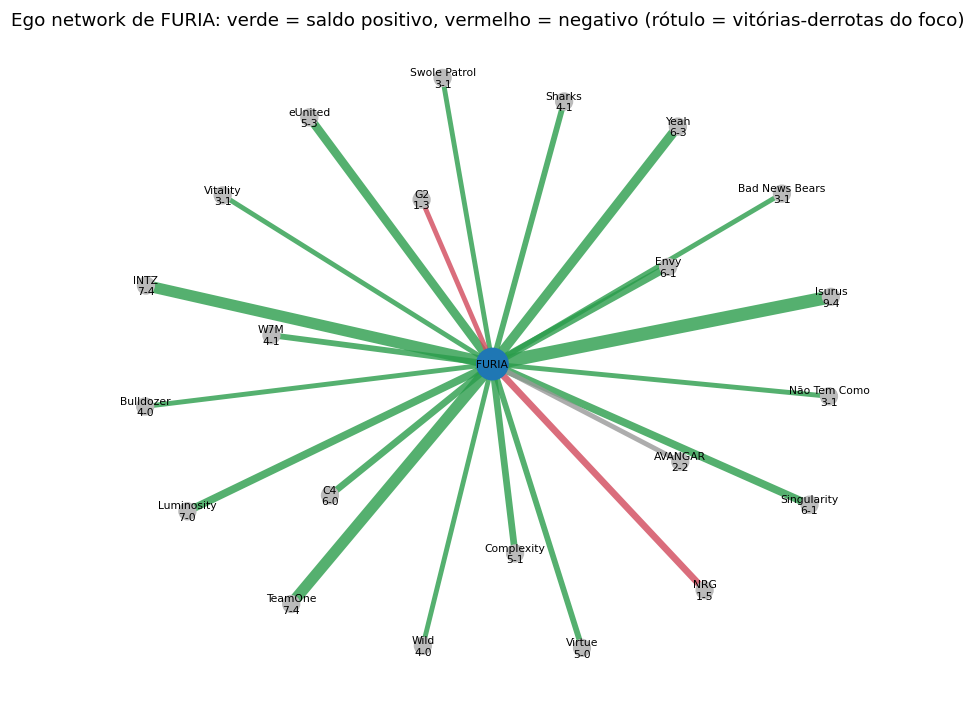

In [17]:
TEAM_FOCO = resolve_team(TEAM_FOCO, set(G.nodes), games.index[0], "TEAM_FOCO")
print(f"Time foco: {TEAM_FOCO} (≈ {int(cent.loc[TEAM_FOCO, 'n_matches'])} partidas na rede)\n")
f = pairs[pairs.dominante == TEAM_FOCO].sort_values("excess", ascending=False)
print(f"Fregueses de {TEAM_FOCO} (vence mais do que o ranking prevê):")
print(f.head(8)[["freguês", "n", "wins", "win_rate", "p_exp", "excess", "pval"]].round(3).to_string(index=False))
g_ = pairs[pairs.freguês == TEAM_FOCO].sort_values("excess", ascending=False)
print(f"\nDe quem {TEAM_FOCO} é freguês (perde mais do que o ranking prevê):")
print(g_.head(8)[["dominante", "n", "wins", "win_rate", "p_exp", "excess", "pval"]].round(3).to_string(index=False))

# Ego network: vizinhos mais frequentes; verde = vitórias do foco, vermelho = derrotas
nb = sorted(set(G.predecessors(TEAM_FOCO)) | set(G.successors(TEAM_FOCO)), key=lambda t: -(G.get_edge_data(t, TEAM_FOCO, {"weight": 0})["weight"] + G.get_edge_data(TEAM_FOCO, t, {"weight": 0})["weight"]))[:22]
E = G.subgraph([TEAM_FOCO] + nb).copy()
# uma aresta por adversário: cor = saldo do foco (verde: mais vitórias; vermelho: mais derrotas), espessura = nº de jogos
w_f = {t: G.get_edge_data(t, TEAM_FOCO, {"weight": 0})["weight"] for t in nb}     # vitórias do foco sobre t
l_f = {t: G.get_edge_data(TEAM_FOCO, t, {"weight": 0})["weight"] for t in nb}     # derrotas do foco para t
Ee = nx.Graph()
Ee.add_node(TEAM_FOCO)
for t in nb:
    Ee.add_edge(TEAM_FOCO, t)
pos = nx.spring_layout(Ee, seed=SEED, k=.9)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for t in nb:
    col = "#2a9d4b" if w_f[t] > l_f[t] else ("#d1495b" if w_f[t] < l_f[t] else "#999999")
    nx.draw_networkx_edges(Ee, pos, edgelist=[(TEAM_FOCO, t)], width=.8 + .6 * (w_f[t] + l_f[t]), edge_color=col, alpha=.8, ax=ax)
nx.draw_networkx_nodes(Ee, pos, node_size=[420 if n == TEAM_FOCO else 120 for n in Ee], node_color=["#1f77b4" if n == TEAM_FOCO else "#bbbbbb" for n in Ee], ax=ax)
nx.draw_networkx_labels(Ee, pos, labels={n: (n if n == TEAM_FOCO else f"{n}\n{w_f[n]}-{l_f[n]}") for n in Ee}, font_size=7, ax=ax)
ax.set_title(f"Ego network de {TEAM_FOCO}: verde = saldo positivo, vermelho = negativo (rótulo = vitórias-derrotas do foco)"); ax.axis("off")
savefig("06_ego_network"); plt.show()

### 7.1 Intransitividade: o ranking é uma hierarquia "limpa"?
Se existisse hierarquia perfeita, ninguém formaria ciclos: A bate B, B bate C **e** A bate C. Um ciclo
A→B→C→A é uma **tríade cíclica**. Construímos o grafo de **dominância líquida** (aresta dominante→dominado
se um lado venceu mais vezes; empates ficam de fora) e contamos tríades com o **censo de tríades** (S4:
triângulos): `030T` = transitiva, `030C` = cíclica.

**Referência:** se orientássemos as mesmas arestas ao acaso, 25% dos triângulos seriam cíclicos. Se o
observado for bem menor, há hierarquia; se for próximo de 25%, a rede é quase "pedra-papel-tesoura".

In [18]:
D = nx.DiGraph()
for u, v, d in G.edges(data=True):                 # u perdeu para v, d['weight'] vezes
    back = G[v][u]["weight"] if G.has_edge(v, u) else 0
    if d["weight"] > back:
        D.add_edge(v, u)                           # v domina u

cen = nx.triadic_census(D)
c_cyc, c_tr = cen["030C"], cen["030T"]
frac_obs = c_cyc / (c_cyc + c_tr) if (c_cyc + c_tr) else np.nan

und_edges = list(D.edges)
fr_rand = []
for _ in range(10):
    Dr = nx.DiGraph()
    flip = rng.random(len(und_edges)) < .5
    Dr.add_edges_from([(b, a) if f_ else (a, b) for (a, b), f_ in zip(und_edges, flip)])
    cr = nx.triadic_census(Dr)
    fr_rand.append(cr["030C"] / (cr["030C"] + cr["030T"]))
print(f"Tríades transitivas (030T): {c_tr:,} · cíclicas (030C): {c_cyc:,}")
print(f"Fração cíclica observada: {frac_obs:.3f} · com orientação aleatória: {np.mean(fr_rand):.3f} ± {np.std(fr_rand):.3f}")
RESULTS.update(triads_trans=int(c_tr), triads_cyc=int(c_cyc), frac_cyc=frac_obs, frac_cyc_rand=float(np.mean(fr_rand)))

Tríades transitivas (030T): 38,957 · cíclicas (030C): 6,778
Fração cíclica observada: 0.148 · com orientação aleatória: 0.249 ± 0.002


## 8. Q2b: Quão provável é o time A vencer o B? (Semanas 2 e 4)

**Cuidado central: vazamento temporal.** Calcular a centralidade com *todas* as partidas e depois "prever" uma
dessas partidas é trapaça: o resultado já está dentro do grafo. Por isso usamos **validação progressiva
(walk-forward)**: para cada trimestre, o grafo é construído **só com partidas anteriores** a ele, e as
características das partidas do trimestre vêm desse grafo.

**Características** (diferença entre `team_1` e `team_2`, em *percentis*, para tornar escalas comparáveis):
razão de vitórias suavizada $\ln\frac{w+1}{l+1}$ (S2), **autovetor** no maior SCC (S4) e PageRank (extra).
**Baseline:** diferença de ranking HLTV. O teste é cronológico: o último `TEST_FRAC` das partidas.
Se a rede agrega algo, o modelo "ranking + rede" deve superar o baseline fora da amostra.

In [19]:
def graph_scores(m):
    """Percentis de s_ratio, eig e pr dos times, calculados só com as partidas de `m`."""
    Gm = build_win_graph(m)
    s = pd.DataFrame(index=list(Gm.nodes))
    w = pd.Series(dict(Gm.in_degree(weight="weight"))); l_ = pd.Series(dict(Gm.out_degree(weight="weight")))
    s["s_ratio"] = np.log((w + 1) / (l_ + 1))
    s["pr"] = pd.Series(nx.pagerank(Gm, weight="weight"))
    s["eig"] = 0.0
    big = max(nx.strongly_connected_components(Gm), key=len)
    if len(big) >= 3:
        try:
            e = nx.eigenvector_centrality_numpy(Gm.subgraph(big), weight="weight", max_iter=1000)
            s.loc[list(e.keys()), "eig"] = pd.Series(e).abs()
        except Exception:
            pass
    return s.rank(pct=True)


mf = mm.sort_values("date").reset_index(drop=True)
mf["q"] = mf.date.dt.to_period("Q")
WARMUP = min(800, int(0.15 * len(mf)))
feat = []
for q in sorted(mf.q.unique()):
    past = mf[mf.q < q]
    if len(past) < WARMUP:
        continue
    sc = graph_scores(past)
    cur = mf[mf.q == q]
    cur = cur[cur.team_1.isin(sc.index) & cur.team_2.isin(sc.index)]
    if cur.empty:
        continue
    f_ = pd.DataFrame({"date": cur.date.values, "y": cur.y.values, "dlr": cur.dlr.values})
    for c in sc.columns:
        f_["d_" + c] = sc.loc[cur.team_1, c].values - sc.loc[cur.team_2, c].values
    feat.append(f_)
F = pd.concat(feat, ignore_index=True)
print(f"Partidas com características fora da amostra: {len(F):,} de {len(mf):,} "
      f"({100 * len(F) / len(mf):.0f}%; o restante é aquecimento ou time ainda sem histórico)")

cut = int(len(F) * (1 - TEST_FRAC))
fit_, test_ = F.iloc[:cut], F.iloc[cut:]
print(f"Ajuste: {len(fit_):,} partidas ({fit_.date.min().date()} → {fit_.date.max().date()}) · "
      f"Teste: {len(test_):,} ({test_.date.min().date()} → {test_.date.max().date()})")

Partidas com características fora da amostra: 18,057 de 22,973 (79%; o restante é aquecimento ou time ainda sem histórico)
Ajuste: 12,639 partidas (2016-07-01 → 2018-12-06) · Teste: 5,418 (2018-12-06 → 2020-03-18)


                     modelo    acc  logloss  brier  ±IC95 acc
    Ranking HLTV (baseline) 0.6530   0.6337 0.2213     0.0127
     Razão de vitórias (S2) 0.6102   0.6559 0.2320     0.0130
             Autovetor (S4) 0.5999   0.6685 0.2374     0.0130
           PageRank (extra) 0.5906   0.6717 0.2392     0.0131
Ranking + autovetor + razão 0.6460   0.6247 0.2177     0.0127
              Sempre team_1 0.5478      NaN    NaN        NaN
                Moeda (0,5) 0.5000   0.6931 0.2500        NaN


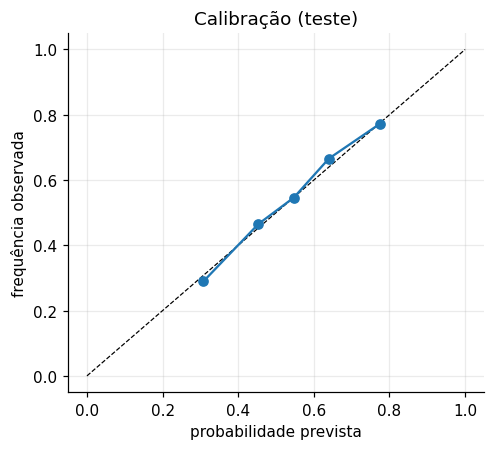

In [20]:
models = {
    "Ranking HLTV (baseline)": ["dlr"],
    "Razão de vitórias (S2)": ["d_s_ratio"],
    "Autovetor (S4)": ["d_eig"],
    "PageRank (extra)": ["d_pr"],
    "Ranking + autovetor + razão": ["dlr", "d_eig", "d_s_ratio"],
}
rows, preds = [], {}
for name, cols_ in models.items():
    w = fit_logit(fit_[cols_].values, fit_.y.values)
    p = predict_logit(w, test_[cols_].values)
    m_ = clf_metrics(test_.y.values, p)
    preds[name] = (w, p)
    rows.append({"modelo": name, **m_, "±IC95 acc": 1.96 * np.sqrt(m_["acc"] * (1 - m_["acc"]) / len(test_))})
rows.append({"modelo": "Sempre team_1", "acc": float(test_.y.mean()), "logloss": np.nan, "brier": np.nan, "±IC95 acc": np.nan})
rows.append({"modelo": "Moeda (0,5)", "acc": 0.5, "logloss": float(np.log(2)), "brier": .25, "±IC95 acc": np.nan})
pred_tab = pd.DataFrame(rows)
print(pred_tab.round(4).to_string(index=False))
pred_tab.to_csv(OUT_DIR / "q2b_previsao.csv", index=False)
RESULTS["pred"] = pred_tab.set_index("modelo")[["acc", "logloss"]].round(4).to_dict("index")
RESULTS["n_test"] = len(test_)

# Calibração do melhor modelo combinado: a probabilidade dita bate com a frequência observada?
w_c, p_c = preds["Ranking + autovetor + razão"]
bins = pd.qcut(pd.Series(p_c), 5, duplicates="drop")
cal = pd.DataFrame({"p": p_c, "y": test_.y.values, "bin": bins.values}).groupby("bin", observed=True).agg(p_medio=("p", "mean"), freq_obs=("y", "mean"), n=("y", "size"))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.plot(cal.p_medio, cal.freq_obs, "o-")
ax.set_xlabel("probabilidade prevista"); ax.set_ylabel("frequência observada"); ax.set_title("Calibração (teste)")
savefig("07_calibracao"); plt.show()

In [21]:
# Função final: P(A vence B) usando o modelo combinado e o grafo completo (tudo que se sabe até hoje)
sc_full = graph_scores(mm)
w_all = fit_logit(F[["dlr", "d_eig", "d_s_ratio"]].values, F.y.values)
last_rank = rk.assign(date=pd.concat([matches_f.date, matches_f.date]).values).sort_values("date").groupby("team")["rank"].last()


def prob_vitoria(a, b):
    """P(a vence b) pelo modelo 'ranking + autovetor + razão de vitórias'. Usa o ranking mais recente conhecido."""
    for t in (a, b):
        if t not in sc_full.index or t not in last_rank.index:
            return None
    x = [[np.log(last_rank[b]) - np.log(last_rank[a]),
          sc_full.loc[a, "eig"] - sc_full.loc[b, "eig"],
          sc_full.loc[a, "s_ratio"] - sc_full.loc[b, "s_ratio"]]]
    return float(predict_logit(w_all, x)[0])


TEAM_ALVO = resolve_team(TEAM_ALVO, set(G.nodes), cent.wins.idxmax(), "TEAM_ALVO")
for a_, b_ in [(TEAM_FOCO, TEAM_ALVO), (TEAM_ALVO, TEAM_FOCO)]:
    pv = prob_vitoria(a_, b_)
    print(f"P({a_} vence {b_}) = " + (f"{pv:.1%}" if pv is not None else "indisponível (time sem histórico)"))
print("\n(Um modelo assim é útil para *ordenar* favoritos; ele não vê elenco, forma recente, mapa nem formato.)")

P(FURIA vence Natus Vincere) = 21.5%
P(Natus Vincere vence FURIA) = 79.9%

(Um modelo assim é útil para *ordenar* favoritos; ele não vê elenco, forma recente, mapa nem formato.)


## 9. Q3: Vetos de mapa (Semanas 2 e 6)

### 9.1 Modelagem bipartida
- **Dois tipos de nó:** times e mapas. **Aresta** time–mapa com **peso = nº de vezes que o time baniu o mapa**
  (outra versão: picks).
- **Normalização pela exposição.** Em cada partida o *pool* de mapas é conhecido (os mapas que aparecem no veto).
  Um time só pode banir um mapa que estava no pool. Então a taxa de ban é *bans ÷ partidas em que o mapa estava
  disponível*, o que neutraliza mudanças no *map pool* ao longo dos anos.
- **Suavização.** Times com poucas partidas dão taxas instáveis; adicionamos *k* pseudo-observações da taxa
  geral do mapa (encolhimento bayesiano simples).
- **Lift** = taxa suavizada do time ÷ taxa geral do mapa; lift > 1 = o time bane esse mapa mais que a média.

### 9.2 Projeção (Semana 6)
A matriz de incidência $B$ (times × mapas) projeta-se sobre os times como $C = B B^T$: dois times são
vizinhos se baniram os mesmos mapas. **Artefato:** o peso bruto de $C$ cresce com o **volume** de partidas, e times
muito ativos viram "hubs" falsos. O remédio é normalizar, aqui com o **Jaccard ponderado** sobre os perfis de
taxa. Mostramos os dois lado a lado.

In [22]:
pk = picks_raw.copy()
pk["date"] = pd.to_datetime(pk["date"], errors="coerce")
pk["team_1"] = pk["team_1"].map(canon_name)
pk["team_2"] = pk["team_2"].map(canon_name)
pk = pk.drop_duplicates("match_id")

# --- slots vazios do veto: "0.0" e "Default" NÃO são mapas -------------------------------------------
# Em partidas bo3/bo5 (e em registros incompletos), os slots que não existem naquele formato vêm como 0/0.0 e há mapas
# "Default" (desconhecido). Tratar isso como um mapa criaria um "mapa 0.0" falso (banido em ~65% das partidas!), que
# inflaria o pool, a projeção e o Jaccard. Aqui eles viram ausentes (NaN) e partidas com pool incompleto saem da análise.
slot_cols = [c for c in pk.columns if re.fullmatch(r"t[12]_(removed|picked)_\d+", c)] + (["left_over"] if "left_over" in pk.columns else [])
BLANK = {"", "0", "0.0", "nan", "none", "default", "-"}


def is_blank(x):
    return pd.isna(x) or str(x).strip().lower() in BLANK


n_cells = pk[slot_cols].size
n_blank = int(sum(pk[c].map(is_blank).sum() for c in slot_cols))
for c in slot_cols:
    pk[c] = pk[c].map(lambda x: np.nan if is_blank(x) else norm_map(x))
print(f"Slots de veto vazios/zerados (0, 0.0, Default): {n_blank:,} de {n_cells:,} ({100 * n_blank / n_cells:.1f}%): tratados como ausentes")
if "best_of" in pk.columns:
    nb = pk[[c for c in slot_cols if "removed" in c]].notna().sum(axis=1).rename("bans válidos")
    print("Bans válidos por partida, segundo o formato (best_of):")
    print(pd.crosstab(pk["best_of"], nb).to_string())

pool_n = pk[slot_cols].apply(lambda r: r.dropna().nunique(), axis=1)      # mapas distintos registrados por partida
pool_alvo = int(pool_n.mode().iloc[0])                                     # tamanho típico do pool (em geral 7)
completa = pool_n >= pool_alvo
print(f"\nMapas distintos registrados por partida: {pool_n.value_counts().sort_index().to_dict()}")
print(f"Partidas com pool completo (≥ {pool_alvo} mapas): {int(completa.sum()):,} de {len(pk):,}; as demais ficam fora da análise de vetos.")
RESULTS.update(veto_blank_pct=100 * n_blank / n_cells, veto_dropped=int((~completa).sum()), pool_alvo=pool_alvo)
pk = pk[completa].copy()

rem_cols = sorted(c for c in pk.columns if re.fullmatch(r"t[12]_removed_\d+", c))
pick_cols = sorted(c for c in pk.columns if re.fullmatch(r"t[12]_picked_\d+", c))
HAS_VETO = bool(rem_cols)
print(f"Colunas de ban: {rem_cols}\nColunas de pick: {pick_cols}\nleft_over presente: {'left_over' in pk.columns}")

if HAS_VETO:
    # --- checagens de interpretação das colunas t1_*/t2_* ---------------------------------------
    first = res.drop_duplicates("match_id").set_index("match_id")[["team_1", "team_2"]]
    j = pk.join(first, on="match_id", rsuffix="_res").dropna(subset=["team_1_res"])
    same = ((j.team_1 == j.team_1_res) & (j.team_2 == j.team_2_res)).mean()
    swap = ((j.team_1 == j.team_2_res) & (j.team_2 == j.team_1_res)).mean()
    print(f"\nTimes em picks vs results (mesmo match_id): mesma ordem {same:.1%} · ordem invertida {swap:.1%}")
    if "inverted_teams" in pk.columns:
        print(pd.crosstab(j.inverted_teams, (j.team_1 == j.team_1_res)).rename_axis(index="inverted_teams", columns="mesma ordem"))
    print("As colunas t1_*/t2_* são atribuídas a team_1/team_2 de picks.csv (os nomes são lidos da própria tabela).")

    # --- tabela longa de ações (ban/pick) ---------------------------------------------------------
    recs = []
    for c in rem_cols + pick_cols:
        side, order = c[1], int(c.rsplit("_", 1)[1])
        t = pk[["match_id", "date", f"team_{side}", c]].dropna(subset=[c]).rename(columns={f"team_{side}": "team", c: "map"})
        t["action"] = "ban" if "removed" in c else "pick"
        t["order"] = order
        recs.append(t)
    veto = pd.concat(recs, ignore_index=True)
    veto["map"] = veto["map"].map(norm_map)

    # --- pool de cada partida e exposição por (time, mapa) ---------------------------------------
    mapcols = rem_cols + pick_cols + (["left_over"] if "left_over" in pk.columns else [])
    pool = pk[["match_id"] + mapcols].melt(id_vars="match_id", value_name="map").dropna(subset=["map"])[["match_id", "map"]]
    pool["map"] = pool["map"].map(norm_map)
    pool = pool.drop_duplicates()
    tm = pd.concat([pk[["match_id", "team_1"]].rename(columns={"team_1": "team"}),
                    pk[["match_id", "team_2"]].rename(columns={"team_2": "team"})])
    expo = pool.merge(tm, on="match_id").groupby(["team", "map"]).size().rename("expo")
    nveto = tm.groupby("team")["match_id"].nunique()

    # mapas "reais" do pool (descarta ruído raro) e times com volume mínimo
    maps_pool = sorted(pool["map"].value_counts()[lambda s: s >= 0.01 * len(pk)].index)
    teams_v = sorted(nveto[nveto >= MIN_VETO].index)

    Bban = (veto[veto.action == "ban"].groupby(["team", "map"]).size().rename("bans").to_frame()
            .join(expo, how="outer").fillna(0).reset_index())
    Bban = Bban[Bban["map"].isin(maps_pool) & Bban.team.isin(teams_v)]
    B = Bban.pivot(index="team", columns="map", values="bans").reindex(index=teams_v, columns=maps_pool).fillna(0)
    E = Bban.pivot(index="team", columns="map", values="expo").reindex(index=teams_v, columns=maps_pool).fillna(0)

    p_map = B.sum() / E.sum()                       # taxa geral de ban de cada mapa
    K = 5
    rate_s = (B + K * p_map) / (E + K)              # taxa suavizada
    lift = rate_s / p_map

    print(f"\nVetos registrados: {len(pk):,} partidas ({pk.date.min().date()} → {pk.date.max().date()})")
    print(f"Mapas no pool: {maps_pool}")
    print(f"Times com ≥ {MIN_VETO} partidas com veto: {len(teams_v)}")
    print("\nTaxa geral de ban por mapa (todos os times):")
    print(p_map.sort_values(ascending=False).round(3).to_string())
    RESULTS.update(veto_matches=len(pk), n_teams_veto=len(teams_v), maps_pool=maps_pool)
else:
    print("⚠️ picks.csv não tem colunas t1_removed_*/t2_removed_*: seção de vetos pulada.")

Slots de veto vazios/zerados (0, 0.0, Default): 32,095 de 144,315 (22.2%): tratados como ausentes
Bans válidos por partida, segundo o formato (best_of):
bans válidos   3      4   5     6
best_of                          
1              0    160  34  5462
1(Online)      0      0   0     2
2              0    222   2     0
2(Online)      0      1   0     0
3             14  10101   4    23
3(LAN)         0      3   0     0
3(Online)      0      1   0     0
3.             0      3   0     0
of             0      3   0     0

Mapas distintos registrados por partida: {6: 25, 7: 16010}
Partidas com pool completo (≥ 7 mapas): 16,010 de 16,035; as demais ficam fora da análise de vetos.
Colunas de ban: ['t1_removed_1', 't1_removed_2', 't1_removed_3', 't2_removed_1', 't2_removed_2', 't2_removed_3']
Colunas de pick: ['t1_picked_1', 't2_picked_1']
left_over presente: True

Times em picks vs results (mesmo match_id): mesma ordem 46.9% · ordem invertida 53.1%
mesma ordem     False  True 
inverted_te

### 9.3 Resposta: que mapa cada time tende a banir?
Tabela do time foco (taxa bruta, suavizada e *lift*), seguida do **primeiro ban** de cada time (o ban mais
"livre": é feito antes de saber a escolha do adversário) e do mapa de calor de *lift* dos times mais ativos.

Perfil de ban de FURIA (194 partidas com veto):
             partidas c/ mapa no pool   bans  taxa bruta  taxa suavizada   lift  1º ban
map                                                                                    
Dust2                           158.0  144.0       0.911           0.894  2.701   133.0
Train                           194.0   67.0       0.345           0.345  1.078    10.0
Mirage                          194.0   40.0       0.206           0.208  0.750    14.0
Nuke                            194.0   51.0       0.263           0.266  0.696    23.0
Overpass                        194.0   44.0       0.227           0.230  0.649    11.0
Cache                           113.0   24.0       0.212           0.219  0.586     2.0
Inferno                         193.0   31.0       0.161           0.164  0.572     0.0
Vertigo                          81.0   13.0       0.160           0.176  0.418     1.0
Cobblestone                      36.0    3.0       0.083           0.114

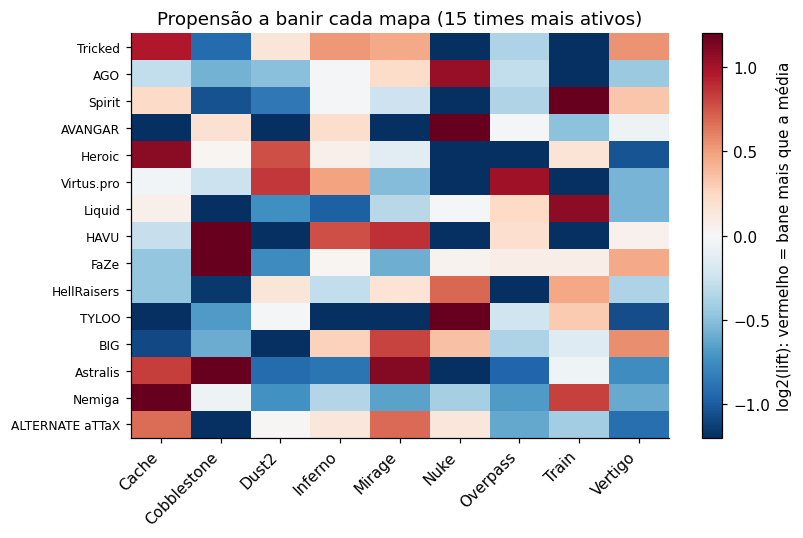


Mapa mais 'característico' de ban (maior lift) por time: {'Nuke': 52, 'Train': 45, 'Dust2': 36, 'Inferno': 35, 'Overpass': 34, 'Mirage': 31, 'Cobblestone': 29, 'Cache': 23, 'Vertigo': 20}


In [23]:
if HAS_VETO:
    tf = TEAM_FOCO if TEAM_FOCO in B.index else nveto[teams_v].idxmax()
    if tf != TEAM_FOCO:
        print(f"⚠️ {TEAM_FOCO} sem dados de veto suficientes; usando {tf}.")
    prof = pd.DataFrame({"partidas c/ mapa no pool": E.loc[tf], "bans": B.loc[tf], "taxa bruta": B.loc[tf] / E.loc[tf].replace(0, np.nan),
                         "taxa suavizada": rate_s.loc[tf], "lift": lift.loc[tf]}).sort_values("lift", ascending=False)
    fb = veto[(veto.action == "ban") & (veto.order == 1) & (veto.team == tf)]["map"].value_counts().rename("1º ban")
    print(f"Perfil de ban de {tf} ({int(nveto[tf])} partidas com veto):")
    print(prof.join(fb).fillna(0).round(3).to_string())
    prof.to_csv(OUT_DIR / "q3_perfil_ban_time_foco.csv")

    top_t = nveto[teams_v].sort_values(ascending=False).head(15).index
    fig, ax = plt.subplots(figsize=(7.5, 5))
    im = ax.imshow(np.log2(lift.loc[top_t].values), cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
    ax.set_xticks(range(len(maps_pool))); ax.set_xticklabels(maps_pool, rotation=45, ha="right")
    ax.set_yticks(range(len(top_t))); ax.set_yticklabels(top_t, fontsize=8); ax.grid(False)
    plt.colorbar(im, ax=ax, label="log2(lift): vermelho = bane mais que a média")
    ax.set_title("Propensão a banir cada mapa (15 times mais ativos)")
    savefig("08_heatmap_bans"); plt.show()

    mode_ban = lift.idxmax(axis=1).value_counts()
    print("\nMapa mais 'característico' de ban (maior lift) por time:", mode_ban.to_dict())

### 9.4 Projeção sobre os times: artefato de volume × Jaccard
Mostramos que o peso bruto de $C=BB^T$ acompanha o volume de partidas (artefato), e que o Jaccard, que
compara **perfis**, não.

In [24]:
if HAS_VETO:
    Bm = B.values
    C_raw = Bm @ Bm.T                                          # projeção bruta (times × times)
    np.fill_diagonal(C_raw, 0)
    P = rate_s.values / rate_s.values.sum(1, keepdims=True)     # perfis (distribuição de bans)
    assert len(P) <= 1500, "muitos times para o Jaccard denso; aumente MIN_VETO"
    J = weighted_jaccard(P)
    np.fill_diagonal(J, 0)

    vol = nveto[teams_v].values
    rho_raw = stats.spearmanr(C_raw.sum(1), vol)[0]
    rho_j = stats.spearmanr(J.sum(1), vol)[0]
    print(f"Correlação (força na projeção × nº de partidas):  bruta C = BBᵀ: ρ = {rho_raw:.2f} · Jaccard: ρ = {rho_j:.2f}")
    RESULTS.update(rho_proj_raw=rho_raw, rho_proj_jaccard=rho_j)

    # esqueleto por limiar: mantém os pares mais parecidos (top 3%)
    iu = np.triu_indices(len(teams_v), 1)
    thr = np.quantile(J[iu], 0.97)
    Sk = nx.Graph()
    Sk.add_nodes_from(teams_v)
    Sk.add_edges_from((teams_v[a], teams_v[b], {"weight": J[a, b]}) for a, b in zip(*iu) if J[a, b] >= thr)
    print(f"Esqueleto por limiar (Jaccard ≥ {thr:.2f}): {Sk.number_of_edges()} arestas · "
          f"{nx.number_connected_components(Sk)} componentes · maior: {len(max(nx.connected_components(Sk), key=len))} times")
    sim = sorted(((J[a, b], teams_v[a], teams_v[b]) for a, b in zip(*iu)), reverse=True)[:8]
    print("\nTimes com perfis de ban mais parecidos (Jaccard):")
    for s_, a_, b_ in sim:
        print(f"  {a_} ~ {b_}: {s_:.2f}")

    # projeção sobre os mapas: mapas banidos pelos mesmos times
    Cm = pd.DataFrame(Bm.T @ Bm, index=maps_pool, columns=maps_pool)
    print("\nProjeção sobre os mapas (co-ban ponderado), diagonal = total de bans:")
    print(Cm.astype(int).to_string())
    Cm.to_csv(OUT_DIR / "q3_projecao_mapas.csv")

Correlação (força na projeção × nº de partidas):  bruta C = BBᵀ: ρ = 0.98 · Jaccard: ρ = -0.12
Esqueleto por limiar (Jaccard ≥ 0.74): 1391 arestas · 14 componentes · maior: 292 times

Times com perfis de ban mais parecidos (Jaccard):
  Naventic ~ subtLe: 0.89
  DarkPassage ~ XPC: 0.87
  Cloud9 ~ fnatic: 0.87
  Riot Squad ~ Se7en: 0.87
  EnVyUs Academy ~ Envy: 0.87
  RESISTANCE ~ UYA: 0.87
  GameAgents ~ UYA: 0.86
  SCARZ Absolute ~ subtLe: 0.86

Projeção sobre os mapas (co-ban ponderado), diagonal = total de bans:
              Cache  Cobblestone   Dust2  Inferno  Mirage    Nuke  Overpass   Train  Vertigo
Cache        515952       212759  257752   348742  382895  426338    406042  395119   136315
Cobblestone  212759       177812  113089   184640  187914  243861    242588  193404    56518
Dust2        257752       113089  268639   231513  234705  296900    288879  260871   105646
Inferno      348742       184640  231513   414912  344797  444018    423644  350921   125913
Mirage       38

### 9.5 Camadas por mapa e a pergunta "o veto é racional?"
**Multicamada (S2):** cada mapa é uma *camada* da rede de confrontos (mesmos nós, arestas diferentes).
Com ela medimos o aproveitamento de cada time **em cada mapa**.

**Hipótese testada:** times banem os mapas em que são **relativamente mais fracos** (aproveitamento no mapa
menos o aproveitamento geral do time). Esperamos correlação **negativa** entre taxa de ban e desempenho relativo.
O teste é feito de dois jeitos: *agrupado* (todos os pares time–mapa) e *dentro de cada time* (que controla
a força do time).

**Ressalva:** quem escolhe um mapa (pick) tende a jogá-lo mais e melhor, e quem bane um mapa o joga menos, então
há seleção. O resultado indica associação, não causa.

Camadas (uma rede de vitórias por mapa):
       mapa  mapas jogados  times  arestas  densidade
      Cache           3769    444     2845     0.0145
Cobblestone           2975    344     2185     0.0185
      Dust2           3474    429     2671     0.0145
    Inferno           6385    513     4555     0.0173
     Mirage           7609    525     5288     0.0192
       Nuke           3655    459     2768     0.0132
   Overpass           4889    511     3653     0.0140
      Train           5677    506     4120     0.0161
    Vertigo            522    173      484     0.0163

Pares time–mapa analisados: 1,807
Agrupado:        ρ(taxa de ban, desempenho relativo) = -0.405 (p = 3.5e-72)
Dentro do time:  ρ mediano = -0.450 · 82% dos times com ρ < 0 (n = 261)


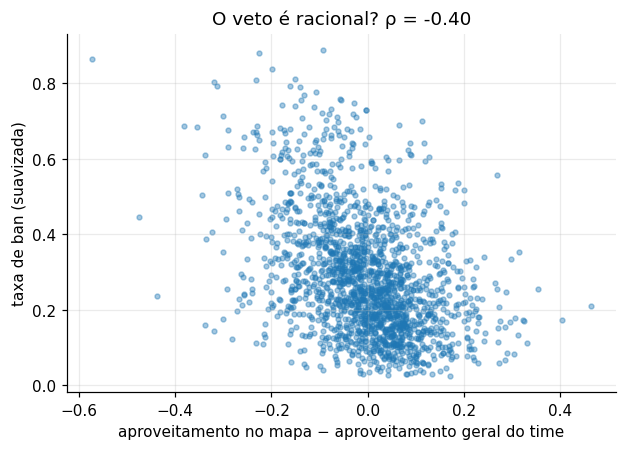


Maiores especialistas por mapa (desempenho no mapa acima do geral do time):
  Cache: Spacestation (+19%) · BigGods (+18%) · EMP (+18%)
  Cobblestone: INTZ (+21%) · CPH Wolves (+17%) · RONIN (+17%)
  Dust2: MK (+27%) · TheMongolz (+18%) · Ground Zero (+16%)
  Inferno: SKADE (+29%) · madlikewizards (+22%) · The Quest (+20%)
  Mirage: Arcade (+27%) · Furious (+23%) · SYF (+18%)
  Nuke: x-kom (+22%) · Gorilla Gang (+22%) · Oceanus (+21%)
  Overpass: PANTHERS (+30%) · WASD (+24%) · Mineski (+21%)
  Train: RuSh3D (+23%) · RED Canids (+23%) · AVEZ (+22%)
  Vertigo: Gambit Youngsters (+21%) · Nordavind (+21%) · Movistar Riders (+12%)


In [25]:
if HAS_VETO:
    a_ = res_ok[["team_1", "map", "map_winner"]].rename(columns={"team_1": "team"}).assign(win=lambda d: (d.map_winner == 1).astype(int))
    b_ = res_ok[["team_2", "map", "map_winner"]].rename(columns={"team_2": "team"}).assign(win=lambda d: (d.map_winner == 2).astype(int))
    mg = pd.concat([a_, b_])
    wr = mg.groupby(["team", "map"])["win"].agg(games="size", wr_map="mean")
    wr_team = mg.groupby("team")["win"].mean().rename("wr_team")

    # camadas: densidade da rede de cada mapa (times filtrados)
    lay = res_ok[res_ok.team_1.isin(G.nodes) & res_ok.team_2.isin(G.nodes)].copy()
    lay["winner"] = np.where(lay.map_winner == 1, lay.team_1, lay.team_2)
    lay["loser"] = np.where(lay.map_winner == 1, lay.team_2, lay.team_1)
    rows = []
    for mp in maps_pool:
        d_ = lay[lay["map"] == mp]
        if d_.empty:
            continue
        gl = build_win_graph(d_)
        rows.append({"mapa": mp, "mapas jogados": len(d_), "times": gl.number_of_nodes(), "arestas": gl.number_of_edges(), "densidade": round(nx.density(gl), 4)})
    print("Camadas (uma rede de vitórias por mapa):")
    print(pd.DataFrame(rows).to_string(index=False))

    Rr = rate_s.stack().rename("ban_rate").reset_index().rename(columns={"level_0": "team", "level_1": "map"})
    Rr.columns = ["team", "map", "ban_rate"]
    Rr = Rr.join(wr, on=["team", "map"]).join(wr_team, on="team")
    Rr = Rr[Rr.games >= MIN_MAP_GAMES].dropna().copy()
    Rr["rel_wr"] = Rr.wr_map - Rr.wr_team
    rho_pool, p_pool = stats.spearmanr(Rr.ban_rate, Rr.rel_wr)

    within = []
    for t, d_ in Rr.groupby("team"):
        if len(d_) >= 4 and d_.ban_rate.nunique() > 1 and d_.rel_wr.nunique() > 1:
            within.append(stats.spearmanr(d_.ban_rate, d_.rel_wr)[0])
    within = np.array(within)
    print(f"\nPares time–mapa analisados: {len(Rr):,}")
    print(f"Agrupado:        ρ(taxa de ban, desempenho relativo) = {rho_pool:.3f} (p = {p_pool:.2g})")
    print(f"Dentro do time:  ρ mediano = {np.median(within):.3f} · {100 * np.mean(within < 0):.0f}% dos times com ρ < 0 (n = {len(within)})")
    RESULTS.update(rho_veto_pool=rho_pool, p_veto_pool=p_pool, rho_veto_within=float(np.median(within)), share_neg_within=float(np.mean(within < 0)), n_veto_pairs=len(Rr))

    fig, ax = plt.subplots(figsize=(5.8, 4.2))
    ax.scatter(Rr.rel_wr, Rr.ban_rate, s=10, alpha=.4)
    ax.set_xlabel("aproveitamento no mapa − aproveitamento geral do time")
    ax.set_ylabel("taxa de ban (suavizada)")
    ax.set_title(f"O veto é racional? ρ = {rho_pool:.2f}")
    savefig("09_veto_racional"); plt.show()

    # "especialistas" por mapa: maior desempenho relativo (com volume mínimo)
    spec = wr.join(wr_team, on="team").query("games >= @MIN_MAP_GAMES * 2").copy()
    spec["especializacao"] = spec.wr_map - spec.wr_team
    print("\nMaiores especialistas por mapa (desempenho no mapa acima do geral do time):")
    for mp in maps_pool:
        s_ = spec.xs(mp, level="map", drop_level=True).sort_values("especializacao", ascending=False).head(3) if mp in spec.index.get_level_values("map") else None
        if s_ is not None and len(s_):
            print(f"  {mp}: " + " · ".join(f"{t} (+{v:.0%})" for t, v in s_["especializacao"].items()))

## 10. Q4: Saltos de vitória até um time-alvo: busca em largura (Semana 3)

**Ideia (curiosidade):** "A venceu quem venceu quem venceu o alvo". Na rede perdedor→vencedor, a **distância a
partir do alvo** é o menor número de vitórias encadeadas que liga cada time ao alvo. É o análogo do *número de
Erdős* e dos seis graus de separação: se for pequeno, a rede é de mundo pequeno.

**Por que BFS e não DFS?** A BFS explora por camadas e **garante o menor caminho** em grafos não ponderados
(tempo O(V+E)). A DFS também é O(V+E), mas mergulha por um caminho e **não** garante o mais curto. Medimos a
diferença: o comprimento do caminho encontrado pela DFS vs. o ótimo da BFS.

Alvo: Natus Vincere
Times que alcançam o alvo por cadeias de vitórias: 525 de 530 (99.1%)
Distância média = 2.57 saltos · máxima = 5
Distribuição (nº de times por distância): {1: 41, 2: 215, 3: 203, 4: 62, 5: 4}

Cadeia mais longa (5 vitórias): Formidable > Breakaway > ORDER > Bravado > Dignitas > Natus Vincere
FURIA está a 2 salto(s) de Natus Vincere: FURIA > AVANGAR > Natus Vincere

BFS × DFS em 40 times: comprimento médio ótimo (BFS) = 2.80 · pela DFS = 258.73 (≈ 92.4× mais longo)


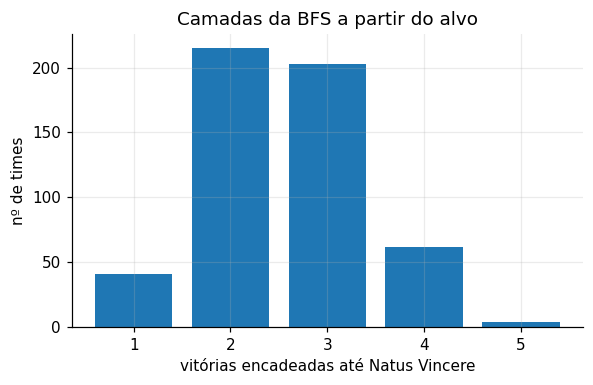

In [26]:
dist = nx.single_source_shortest_path_length(G, TEAM_ALVO)         # BFS a partir do alvo seguindo perdedor→vencedor
dist = {k: v for k, v in dist.items() if k != TEAM_ALVO}
ds = pd.Series(dist)
print(f"Alvo: {TEAM_ALVO}")
print(f"Times que alcançam o alvo por cadeias de vitórias: {len(ds)} de {N - 1} ({100 * len(ds) / (N - 1):.1f}%)")
print(f"Distância média = {ds.mean():.2f} saltos · máxima = {ds.max()}")
print("Distribuição (nº de times por distância):", ds.value_counts().sort_index().to_dict())

far = ds.idxmax()
chain = nx.shortest_path(G, TEAM_ALVO, far)[::-1]
print(f"\nCadeia mais longa ({ds.max()} vitórias): " + " > ".join(chain))
if TEAM_FOCO in ds.index:
    c_ = nx.shortest_path(G, TEAM_ALVO, TEAM_FOCO)[::-1]
    print(f"{TEAM_FOCO} está a {ds[TEAM_FOCO]} salto(s) de {TEAM_ALVO}: " + " > ".join(c_))

# BFS (ótimo) vs. DFS (qualquer caminho)
pred = nx.dfs_predecessors(G, TEAM_ALVO)
sample = rng.choice(ds.index, size=min(40, len(ds)), replace=False)
dfs_len = []
for t in sample:
    n_, k = t, 0
    while n_ != TEAM_ALVO:
        n_ = pred[n_]; k += 1
    dfs_len.append(k)
ratio = np.mean(dfs_len) / ds[list(sample)].mean()
print(f"\nBFS × DFS em {len(sample)} times: comprimento médio ótimo (BFS) = {ds[list(sample)].mean():.2f} · "
      f"pela DFS = {np.mean(dfs_len):.2f} (≈ {ratio:.1f}× mais longo)")
RESULTS.update(bfs_target=TEAM_ALVO, bfs_reach=len(ds) / (N - 1), bfs_mean=float(ds.mean()), bfs_max=int(ds.max()), dfs_ratio=float(ratio))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
vc = ds.value_counts().sort_index()
ax.bar(vc.index, vc.values)
ax.set_xlabel(f"vitórias encadeadas até {TEAM_ALVO}"); ax.set_ylabel("nº de times")
ax.set_title("Camadas da BFS a partir do alvo")
savefig("10_bfs_camadas"); plt.show()

## 11. Q5: Resiliência: o que acontece se removermos os maiores hubs? (Semana 4)

**Pergunta:** o circuito depende de poucos times para se manter "conectado"? Removemos nós em ordem
decrescente de uma medida (ataque dirigido) e comparamos com remoção **aleatória** (falha), acompanhando a
fração do **componente gigante** e o **caminho médio**. Redes com hubs costumam ser robustas a falhas aleatórias
e frágeis a ataques. Aqui testamos se isso vale para a rede de confrontos.

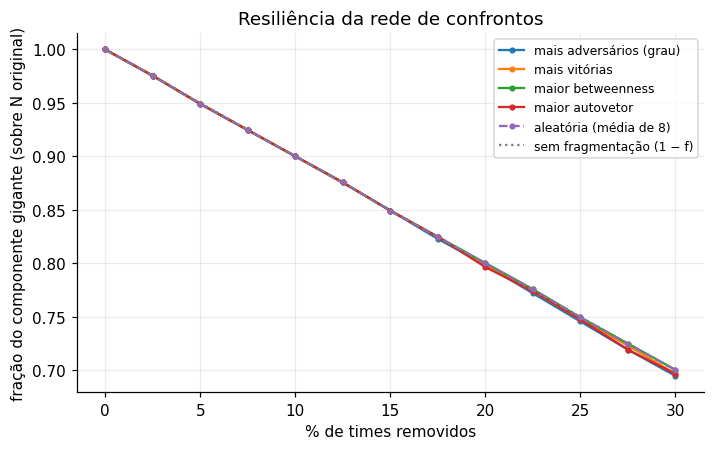

Sem remoção: caminho médio = 2.432 · eficiência global = 0.4510
(GCC = fração sobre o N original; se vale 0,90, nada se desconectou: o dano aparece nos caminhos e na eficiência)
          remoção (10%)  GCC (fração)  caminho médio  eficiência global
mais adversários (grau)           0.9          2.885             0.3834
          mais vitórias           0.9          2.851             0.3906
      maior betweenness           0.9          2.988             0.3765
        maior autovetor           0.9          2.710             0.4072
              aleatória           0.9          2.483             0.4426


In [27]:
if RUN_RESILIENCE:
    N0 = U.number_of_nodes()
    order = {
        "mais adversários (grau)": list(cent["opponents"].sort_values(ascending=False).index),
        "mais vitórias": list(cent["wins"].sort_values(ascending=False).index),
        "maior betweenness": list(cent["betweenness"].fillna(0).sort_values(ascending=False).index),
        "maior autovetor": list(cent["eig"].fillna(0).sort_values(ascending=False).index),
    }
    fracs = np.linspace(0, 0.30, 13)

    def gcc_after(ug, removed):
        Hh = ug.copy(); Hh.remove_nodes_from(removed)
        return (len(max(nx.connected_components(Hh), key=len)) / N0) if Hh.number_of_nodes() else 0.0

    curves = {name: [gcc_after(U, o[:int(round(f * N0))]) for f in fracs] for name, o in order.items()}
    nodes_l = list(U.nodes)
    rand = np.mean([[gcc_after(U, list(rng.permutation(nodes_l)[:int(round(f * N0))])) for f in fracs] for _ in range(8)], axis=0)
    curves["aleatória (média de 8)"] = rand

    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    for name, cv in curves.items():
        ax.plot(fracs * 100, cv, "o-", ms=3, label=name, ls="--" if "aleat" in name else "-")
    ax.plot(fracs * 100, 1 - fracs, ":", color="gray", label="sem fragmentação (1 − f)")
    ax.set_xlabel("% de times removidos"); ax.set_ylabel("fração do componente gigante (sobre N original)"); ax.legend(fontsize=8)
    ax.set_title("Resiliência da rede de confrontos")
    savefig("11_resiliencia"); plt.show()

    # impacto no caminho médio com 10% removidos
    rows = []
    for name, o in list(order.items()) + [("aleatória", list(rng.permutation(nodes_l)))]:
        Hh = U.copy(); Hh.remove_nodes_from(o[:int(round(.10 * N0))])
        gcc_h = largest_cc(Hh)
        rows.append({"remoção (10%)": name, "GCC (fração)": round(gcc_h.number_of_nodes() / N0, 3),
                     "caminho médio": round(path_stats(gcc_h)["avg"], 3), "eficiência global": round(nx.global_efficiency(Hh), 4)})
    base = path_stats(largest_cc(U))["avg"]
    base_eff = nx.global_efficiency(U)
    print(f"Sem remoção: caminho médio = {base:.3f} · eficiência global = {base_eff:.4f}")
    print("(GCC = fração sobre o N original; se vale 0,90, nada se desconectou: o dano aparece nos caminhos e na eficiência)")
    res_tab = pd.DataFrame(rows)
    print(res_tab.to_string(index=False))
    res_tab.to_csv(OUT_DIR / "q5_resiliencia_10pct.csv", index=False)
    RESULTS["resil"] = res_tab.set_index("remoção (10%)").to_dict("index")
    RESULTS["resil_base_path"] = base
    RESULTS["resil_base_eff"] = base_eff
else:
    print("RUN_RESILIENCE = False: seção pulada.")

## 12. Subredes por ano e comparação com o CS2 (bônus; subredes: Semana 2 · k-core: Semana 5)

**Modelagem temporal (alternativa de modelagem).** A mesma rede, fatiada por ano (cada ano é uma **subrede**, S2) (mínimo de 5 partidas por time no ano), mostra se a
estrutura (tamanho, densidade, núcleo) muda com o tempo. Cuidado: o número de partidas registradas muda
entre anos, e isso, sozinho, altera densidade e k-core; compare tendências, não valores absolutos.

**CS2 (opcional).** Se `data/cs2_results.csv` existir (dataset `ilyazored/hltv-match-resultscs2`), o mesmo
pipeline roda nele. **Nunca** misturamos CS:GO e CS2 no mesmo grafo: são jogos, elencos e *map pools*
diferentes, e nomes de times se repetem.

In [28]:
def summarize_graph(m, label, min_year=5):
    games_y = pd.concat([m.winner, m.loser]).value_counts()
    keep_y = set(games_y[games_y >= min_year].index)
    mk = m[m.winner.isin(keep_y) & m.loser.isin(keep_y)]
    if len(mk) < 20:
        return None
    g = build_win_graph(mk)
    u = to_undirected_weighted(g)
    us = nx.Graph(u); us.remove_edges_from(nx.selfloop_edges(us))
    gcc_n = len(max(nx.connected_components(u), key=len))
    wins_y = pd.Series(dict(g.in_degree(weight="weight")))
    return {"recorte": label, "partidas": len(mk), "times": g.number_of_nodes(), "arestas": g.number_of_edges(),
            "densidade": round(nx.density(g), 4), "GCC (%)": round(100 * gcc_n / g.number_of_nodes(), 1),
            "k máx": max(nx.core_number(us).values()), "top-3 (vitórias)": ", ".join(wins_y.sort_values(ascending=False).head(3).index)}


rows = [summarize_graph(d_, str(y)) for y, d_ in matches.groupby(matches.date.dt.year)]
if CS2_FILE.exists():
    cs2 = pd.read_csv(CS2_FILE)
    lc = {c.lower(): c for c in cs2.columns}
    if {"team_won", "team_lost"} <= set(lc) and ("time" in lc or "date" in lc):
        dc = lc.get("time") or lc.get("date")
        canon2, _ = build_canon(cs2[lc["team_won"]], cs2[lc["team_lost"]])
        m2 = pd.DataFrame({"winner": cs2[lc["team_won"]].map(lambda x: canon_name(x, canon2)),
                           "loser": cs2[lc["team_lost"]].map(lambda x: canon_name(x, canon2)),
                           "date": pd.to_datetime(cs2[dc], errors="coerce")}).dropna()
        m2 = m2[m2.winner != m2.loser]
        print(f"CS2: {len(m2):,} partidas · {m2.date.min().date()} → {m2.date.max().date()}")
        rows.append(summarize_graph(m2, "CS2 (arquivo)", min_year=MIN_MATCHES))
    else:
        print("cs2_results.csv encontrado, mas as colunas esperadas (team_won, team_lost, time) não batem:", list(cs2.columns))
else:
    print(f"(CS2 pulado: {CS2_FILE} não existe. É um bônus opcional.)")

temporal = pd.DataFrame([r for r in rows if r])
print()
print(temporal.to_string(index=False))
temporal.to_csv(OUT_DIR / "temporal_e_cs2.csv", index=False)
RESULTS["temporal"] = temporal[["recorte", "times", "densidade", "k máx"]].to_dict("records")

(CS2 pulado: data/cs2_results.csv não existe. É um bônus opcional.)

recorte  partidas  times  arestas  densidade  GCC (%)  k máx             top-3 (vitórias)
   2015       164     25      119     0.1983    100.0      6   Luminosity, fnatic, Liquid
   2016      3598    226     2033     0.0400    100.0     17   Cloud9, Dignitas, Astralis
   2017      6856    365     4295     0.0323    100.0     20             SK, FaZe, Cloud9
   2018      7768    365     4757     0.0358    100.0     22 Astralis, Windigo, Grayhound
   2019      5590    307     3758     0.0400    100.0     22     forZe, Vitality, Tricked
   2020       968    142      867     0.0433    100.0     15           Chaos, Spirit, BIG


## 13. Conclusões

O bloco abaixo **monta o resumo a partir dos números calculados**, de modo que o texto não fique desatualizado
se os parâmetros mudarem. Ele também salva `resultados/resumo.md`, usado no README.

In [29]:
def lvl(x, a=.3, b=.6):
    x = abs(x)
    return "fraca" if x < a else ("moderada" if x < b else "forte")


R_ = RESULTS
L_ = []
L_.append(f"**Dados.** {R_['n_matches_valid']:,} partidas válidas entre {R_['n_teams_all']:,} times; a rede de trabalho "
          f"(≥ {MIN_MATCHES} partidas) tem {R_['N']:,} times e {R_['L']:,} arestas, com densidade {R_['density']:.3f}.")
L_.append(f"**Estrutura (S3/S4).** GCC com {100 * R_['gcc_frac']:.0f}% dos times; caminho médio {R_['avg_path']:.2f} "
          f"(aleatório: {R_['avg_path_rand']:.2f}), clustering {R_['clustering']:.2f} (aleatório: {R_['clustering_rand']:.3f}), σ = {R_['sigma']:.1f}. "
          f"Maior SCC com {100 * R_['scc_frac']:.0f}% dos times.")
cr = R_["corr_rank"]
best = min(cr, key=cr.get)
L_.append(f"**Q1 (hierarquia).** A medida mais alinhada ao ranking HLTV é `{best}` (ρ = {cr[best]:.2f}, {lvl(cr[best])}); "
          f"autovetor: ρ = {cr.get('eig', np.nan):.2f}; nº de adversários: ρ = {cr.get('opponents', np.nan):.2f}.")
L_.append(f"**Q1b (núcleo, S5).** Degenerescência k = {R_['kmax']} com {R_['n_innermost']} times no núcleo interno; "
          f"ρ(core, ranking) = {R_['rho_core_rank']:.2f}, ρ(core, nº de adversários) = {R_['rho_core_deg']:.2f}. "
          f"{'O núcleo acompanha mais o calendário do que a força.' if abs(R_['rho_core_deg']) > abs(R_['rho_core_rank']) else 'O núcleo acompanha o ranking.'}")
tp = R_.get("top_pair")
L_.append(f"**Q2 (freguesia).** {R_['n_pairs_sig']} de {R_['n_pairs']:,} pares passam no teste (FDR 10%) de vencer acima do esperado pelo ranking"
          + (f"; o mais marcante: {tp['dominante']} sobre {tp['freguês']} ({int(tp['wins'])}/{int(tp['n'])})." if tp else "."))
L_.append(f"**Intransitividade.** {100 * R_['frac_cyc']:.1f}% dos triângulos de dominância são cíclicos (aleatório: {100 * R_['frac_cyc_rand']:.1f}%): "
          f"{'há hierarquia, mas imperfeita' if R_['frac_cyc'] < R_['frac_cyc_rand'] else 'sem hierarquia detectável'}.")
pr_ = R_["pred"]
base_acc = pr_["Ranking HLTV (baseline)"]["acc"]; comb_acc = pr_["Ranking + autovetor + razão"]["acc"]
base_ll = pr_["Ranking HLTV (baseline)"]["logloss"]; comb_ll = pr_["Ranking + autovetor + razão"]["logloss"]
ci_acc = 1.96 * np.sqrt(base_acc * (1 - base_acc) / R_["n_test"])
d_acc, d_ll = comb_acc - base_acc, base_ll - comb_ll
net_best = max(["Razão de vitórias (S2)", "Autovetor (S4)", "PageRank (extra)"], key=lambda k: pr_[k]["acc"])
if d_ll > .002 and d_acc > ci_acc:
    q2b_txt = "A rede melhora a acurácia e a qualidade das probabilidades."
elif d_ll > .002:
    q2b_txt = (f"A rede melhora ligeiramente a qualidade das probabilidades (logloss {base_ll:.3f} → {comb_ll:.3f}), mas a acurácia é "
               f"estatisticamente equivalente (Δ = {100 * d_acc:+.1f} p.p., IC95% ≈ ±{100 * ci_acc:.1f}).")
else:
    q2b_txt = "A rede não acrescenta informação mensurável além do ranking nesta amostra."
net_txt = (f" Sozinha, a melhor medida de rede ({net_best}: {pr_[net_best]['acc']:.1%}) fica "
           f"{'abaixo do' if pr_[net_best]['acc'] < base_acc - ci_acc else 'próxima do'} ranking.")
L_.append(f"**Q2b (previsão, teste n = {R_['n_test']:,}).** Ranking sozinho: {base_acc:.1%} de acerto (logloss {base_ll:.3f}); "
          f"ranking + rede: {comb_acc:.1%} (logloss {comb_ll:.3f}). {q2b_txt}{net_txt}")
if "rho_veto_pool" in R_:
    L_.append(f"**Q3 (vetos).** Correlação entre taxa de ban e desempenho relativo no mapa: ρ = {R_['rho_veto_pool']:.2f} (agrupado) e "
              f"{R_['rho_veto_within']:.2f} (mediana dentro dos times; {100 * R_['share_neg_within']:.0f}% negativos). "
              f"{'Os times tendem a banir os mapas em que são relativamente mais fracos.' if R_['rho_veto_within'] < -.1 else 'A associação é fraca: o veto parece guiado por mais do que o desempenho histórico.'} "
              f"Na projeção, o peso bruto acompanha o volume (ρ = {R_['rho_proj_raw']:.2f}) e o Jaccard o neutraliza (ρ = {R_['rho_proj_jaccard']:.2f}).")
L_.append(f"**Q4 (BFS, S3).** {100 * R_['bfs_reach']:.0f}% dos times alcançam {R_['bfs_target']} por cadeias de vitórias; distância média "
          f"{R_['bfs_mean']:.2f}, máxima {R_['bfs_max']}. A DFS acha caminhos ≈ {R_['dfs_ratio']:.1f}× mais longos que o ótimo da BFS.")
if "resil" in R_:
    rz = R_["resil"]
    worst = max((k for k in rz if k != "aleatória"), key=lambda k: rz[k]["caminho médio"])
    gcc_share = rz[worst]["GCC (fração)"] / 0.90          # fração dos times restantes que continuam no componente gigante
    L_.append(f"**Q5 (resiliência).** Remover 10% dos times {'não fragmenta a rede' if gcc_share > .98 else 'fragmenta a rede'} "
              f"({100 * gcc_share:.0f}% dos restantes seguem no componente gigante), mas alonga os caminhos: média de {R_['resil_base_path']:.2f} → "
              f"{rz[worst]['caminho médio']:.2f} no pior ataque ('{worst}'), contra {rz['aleatória']['caminho médio']:.2f} na remoção aleatória; "
              f"a eficiência global cai de {R_['resil_base_eff']:.3f} para {rz[worst]['eficiência global']:.3f}.")

summary = "\n\n".join(L_)
(OUT_DIR / "resumo.md").write_text(summary, encoding="utf-8")
from IPython.display import Markdown, display
display(Markdown(summary))

**Dados.** 26,781 partidas válidas entre 1,539 times; a rede de trabalho (≥ 15 partidas) tem 531 times e 11,314 arestas, com densidade 0.040.

**Estrutura (S3/S4).** GCC com 100% dos times; caminho médio 2.43 (aleatório: 2.05), clustering 0.52 (aleatório: 0.063), σ = 6.9. Maior SCC com 99% dos times.

**Q1 (hierarquia).** A medida mais alinhada ao ranking HLTV é `eig` (ρ = -0.82, forte); autovetor: ρ = -0.82; nº de adversários: ρ = -0.58.

**Q1b (núcleo, S5).** Degenerescência k = 34 com 73 times no núcleo interno; ρ(core, ranking) = -0.66, ρ(core, nº de adversários) = 0.92. O núcleo acompanha mais o calendário do que a força.

**Q2 (freguesia).** 1 de 3,038 pares passam no teste (FDR 10%) de vencer acima do esperado pelo ranking; o mais marcante: Chiefs sobre Legacy (25/25).

**Intransitividade.** 14.8% dos triângulos de dominância são cíclicos (aleatório: 24.9%): há hierarquia, mas imperfeita.

**Q2b (previsão, teste n = 5,418).** Ranking sozinho: 65.3% de acerto (logloss 0.634); ranking + rede: 64.6% (logloss 0.625). A rede melhora ligeiramente a qualidade das probabilidades (logloss 0.634 → 0.625), mas a acurácia é estatisticamente equivalente (Δ = -0.7 p.p., IC95% ≈ ±1.3). Sozinha, a melhor medida de rede (Razão de vitórias (S2): 61.0%) fica abaixo do ranking.

**Q3 (vetos).** Correlação entre taxa de ban e desempenho relativo no mapa: ρ = -0.40 (agrupado) e -0.45 (mediana dentro dos times; 82% negativos). Os times tendem a banir os mapas em que são relativamente mais fracos. Na projeção, o peso bruto acompanha o volume (ρ = 0.98) e o Jaccard o neutraliza (ρ = -0.12).

**Q4 (BFS, S3).** 99% dos times alcançam Natus Vincere por cadeias de vitórias; distância média 2.57, máxima 5. A DFS acha caminhos ≈ 92.4× mais longos que o ótimo da BFS.

**Q5 (resiliência).** Remover 10% dos times não fragmenta a rede (100% dos restantes seguem no componente gigante), mas alonga os caminhos: média de 2.43 → 2.99 no pior ataque ('maior betweenness'), contra 2.48 na remoção aleatória; a eficiência global cai de 0.451 para 0.377.

### 13.1 Resposta à pergunta central
> ✍️ **A PREENCHER PELO AUTOR** depois de rodar com os dados reais e ler o resumo acima. Este bloco é a interpretação
> do autor, não um texto gerado: substitua o roteiro abaixo por 1 ou 2 parágrafos com a resposta.

> *A posição estrutural de um time na rede de confrontos explica seu desempenho além do ranking HLTV?*

Um roteiro para responder com base nos números:
1. **Concordância (Q1):** as centralidades acompanham o ranking? Qual delas mais? Isso valida a rede como retrato da força real?
2. **Informação nova (Q2/Q2b):** existem relações (freguesias) que o ranking não prevê? A rede melhora a previsão fora da amostra,
   ou só reproduz o ranking?
3. **Estrutura (Q1b/Q4/Q5):** o núcleo é "elite" ou "calendário"? A rede é de mundo pequeno? Depende de poucos hubs?
4. **Estratégia (Q3):** os vetos seguem o desempenho por mapa?

### 13.2 Limitações e artefatos (o que esta análise **não** responde)
- **Time ≠ elenco.** Um nó é um rótulo que atravessa várias formações; trocas de jogadores diluem os resultados. A rede jogador–time (`players.csv`) seria o próximo passo.
- **Amostragem.** O HLTV registra mais os times grandes; times pequenos aparecem pouco e quase só contra vizinhos de ranking. O filtro de volume (seção 2.7) reduz o ruído, mas introduz viés de seleção.
- **Rede estática.** Misturar 2015–2020 numa rede única ignora a evolução dos times (seção 12 mostra a mudança de estrutura entre anos).
- **Centralidade ≠ demanda/força causal.** O autovetor mede *com quem* se venceu; não mede mapa, formato (bo1/bo3/bo5) ou forma recente.
- **K-core reflete calendário** (nº de adversários distintos), não só força.
- **Testes múltiplos.** Centenas de pares testados em "freguesia": usamos FDR, mas ainda é uma análise exploratória.
- **Previsão.** Sem vazamento temporal (walk-forward), mas o modelo só usa ranking e resultados passados; não vê elenco, lesões, mapa, formato.
- **Vetos.** O formato (bo1/bo3/bo5) e a ordem de bans mudam o significado de um ban; o *map pool* mudou ao longo dos anos (tratado pela exposição por partida). A relação ban × desempenho sofre seleção (quem escolhe o mapa joga mais nele).
- **Dados terminam em 03/2020** (CS:GO). Não descrevem o CS2.

### 13.3 Próximos passos
- Rede **jogador–time** (bipartida) para capturar mobilidade de elenco e "pontes" entre times (S6 + S5).
- **Grafo temporal em janelas deslizantes** em vez de fatias anuais.
- Incluir **formato (bo1/bo3/bo5)** e **mapa** como camadas; modelar picks além de bans.
- Repetir o pipeline com dados **CS2** mais recentes e com ranking contemporâneo.

## Referências
- Machado, M. D. *CS:GO Professional Matches*. Kaggle. https://www.kaggle.com/datasets/mateusdmachado/csgo-professional-matches (dados do HLTV.org).
- ilyazored. *HLTV Match Results | CS2*. Kaggle (opcional). https://www.kaggle.com/datasets/ilyazored/hltv-match-resultscs2
- Hagberg, Schult, Swart. *NetworkX*. https://networkx.org
- Material da disciplina (Algoritmos e Estruturas de Dados II), Semanas 2 a 6.